# IEEE-CIS EDA and Leakage Audit — Kaggle-Modular Thesis Edition

**Refined from:** Kaggle kernel `iemanihsan/ieee-cis-eda-leakage-audit` (version 3).
The source notebook is preserved unchanged; this is a separate artifact.

## Notebook architecture

This file intentionally remains a single Kaggle notebook script with the original
15-section thesis narrative. Modularity is achieved inside the notebook by keeping
each section in three layers where applicable: reusable definitions, a small
orchestration block, and presentation/export code. Public helper interfaces are
preserved unless a correctness fix requires an explicit new argument.

The design goal is a restart-and-run-all artifact that is readable in Kaggle, while
still allowing the statistical, leakage, decision and export components to be
tested independently.

## Research questions

This notebook produces evidence for seven questions, and nothing else:

| # | Question | Sections |
|---|---|---|
| RQ1 | **Leakage risk** — can any development decision be traced to out-of-time data? | 3, 15 |
| RQ2 | **Temporal feature validity** — which features change distribution across the development period? | 5, 10 |
| RQ3 | **Distribution drift** — how large is the shift, on a stated scale, with stated sample sizes? | 5 |
| RQ4 | **Missingness stability** — is "this field is blank" a stable signal, or a product-mix artefact? | 6 |
| RQ5 | **Redundant feature stability** — do the V-series redundancy groups reproduce across blocks? | 7 |
| RQ6 | **Graph-entity readiness** — what coverage, persistence and cold-start exposure do the candidate entity columns carry? | 8 |
| RQ7 | **OOT generalization risk** — what is known about the holdout *without* letting it influence any decision? | 3, 8, 12 |

## Scope: exploratory versus confirmatory

Everything in this notebook is **exploratory and descriptive**. No hypothesis was
pre-registered before the data were seen, no model is fitted, and no effect is
estimated under an identification strategy. Consequently:

* p-values here are **screening devices with a multiplicity correction**, not
  confirmatory tests. A Benjamini–Hochberg-adjusted p-value below 0.05 licenses
  "worth a closer look", not "established".
* PSI, KS and lift figures are **descriptive statistics with configured decision
  bands**. The bands are choices about review capacity, stated in Section 1 and
  snapshotted into every exported decision.
* Every association reported is **predictive, not causal**. No claim of the form
  "X causes fraud" is made or supported anywhere in this notebook.
* The one **confirmatory-style** element is the leakage protocol itself: the
  quarantine assertions in Section 3 are pass/fail invariants, not exploratory
  findings, and a failure stops the run.

## What changed relative to the source notebook

| Source notebook | This notebook |
|---|---|
| `DRIFT_CORR = 0.30` on Pearson correlation, unsourced | Spearman throughout; the threshold's empirical distribution is shown and a quantile-derived alternative computed (Section 10) |
| Drift judged by one correlation | PSI (dev-learned bin edges) + KS with BH correction + per-block lift stability, combined (Section 5) |
| Missingness patterns tested in aggregate | Same pattern-collapsing, plus ProductCD stratification and an explicit Simpson-type reversal check (Section 6) |
| V-series grouped once on a dev sample, Pearson, union-find | Per-block Spearman hierarchical clustering, cross-block stability, MI-based representative with deterministic tie-breaking (Section 7) |
| Entities described qualitatively | Coverage, cardinality, persistence, degree bands, and OOT cold-start on two explicit denominators (Section 8) |
| Fixed 5-block split | The same diagnostics repeated at 4, 5, 6 and 8 blocks with verdict-change tracking (Section 9) |
| `feature_decisions.csv` | `feature_risk_table.csv`, `decisions_ledger.json`, `run_manifest.json`, `entity_cold_start_summary.csv`, `block_sensitivity_summary.csv` |
| Leakage protocol stated in prose | Registered fitted objects, executable quarantine assertions and a reusable `LeakageAuditor` (Sections 3, 15) |
| `warnings.filterwarnings("ignore")` | Warnings left enabled; failures are logged with their fallback, never swallowed |

## 1. Environment and Reproducibility

Three cells: dependency check, the single configuration dictionary, and the
environment/hashing utilities. Nothing below Section 1 hard-codes a threshold —
every one is read from `CONFIG`, and `CONFIG` is snapshotted into every exported
decision so a result can always be traced back to the rules that produced it.

In [1]:
"""Section 1a - imports and dependency check."""

from __future__ import annotations

import gc
import hashlib
import importlib
import json
import logging
import os
import platform
import sys
import warnings
from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any, Callable, Dict, Iterable, List, Mapping, Optional, Sequence, Tuple
from packaging.version import InvalidVersion, Version

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Warnings are NOT suppressed globally. Relevant warnings are addressed or
# documented in-line. Only this one noisy, understood case is narrowed.
warnings.simplefilter("default")

warnings.filterwarnings(
"ignore",
category=DeprecationWarning,
message=r"datetime\.datetime\.utcnow\(\) is deprecated.*",
)

REQUIRED_PACKAGES = {
    "numpy": "1.23",
    "pandas": "1.5",
    "scipy": "1.9",
    "sklearn": "1.1",
    "matplotlib": "3.5",
}


def check_dependencies(required: Mapping[str, str]) -> pd.DataFrame:
    """Validate imports and minimum package versions.

    Args:
        required: Mapping of importable module name to minimum supported version.

    Returns:
        A dataframe containing the installed version and compatibility result.

    Raises:
        ImportError: If a package is missing.
        RuntimeError: If a package is older than the configured minimum or its
            version cannot be interpreted safely.
    """
    rows: List[Dict[str, Any]] = []
    missing: List[str] = []
    incompatible: List[str] = []

    for name, minimum in sorted(required.items()):
        try:
            module = importlib.import_module(name)
        except ImportError:
            missing.append(name)
            rows.append({
                "package": name,
                "required_min": minimum,
                "installed": None,
                "available": False,
                "compatible": False,
            })
            continue

        installed = getattr(module, "__version__", None)
        compatible = False
        try:
            compatible = installed is not None and Version(installed) >= Version(minimum)
        except InvalidVersion:
            incompatible.append(f"{name}>={minimum} required; found unparseable {installed!r}")
        else:
            if not compatible:
                incompatible.append(f"{name}>={minimum} required; found {installed or 'unknown'}")

        rows.append({
            "package": name,
            "required_min": minimum,
            "installed": installed,
            "available": True,
            "compatible": compatible,
        })

    report = pd.DataFrame(rows)
    if missing:
        raise ImportError(
            "Missing required packages: " + ", ".join(missing)
            + ". Install them before running this notebook; this notebook does "
              "not install packages itself."
        )
    if incompatible:
        raise RuntimeError("Incompatible package versions: " + "; ".join(incompatible))
    return report

DEPENDENCY_REPORT = check_dependencies(REQUIRED_PACKAGES)

from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.feature_selection import mutual_info_classif

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-7s | %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)
LOG = logging.getLogger("leakage_audit")
LOG.info("Imports complete.")
print(DEPENDENCY_REPORT.to_string(index=False))

09:11:51 | INFO    | Imports complete.


   package required_min installed  available  compatible
matplotlib          3.5    3.10.0       True        True
     numpy         1.23     2.0.2       True        True
    pandas          1.5     2.3.3       True        True
     scipy          1.9    1.16.3       True        True
   sklearn          1.1     1.6.1       True        True


In [2]:
"""Section 1b - single configuration object.

Every threshold in this notebook is a *configured decision rule*, not a law of
nature. Changing a value here changes every downstream verdict, and the value
used is snapshotted into run_manifest.json and decisions_ledger.json.
"""

CONFIG: Dict[str, Any] = {
    # --- reproducibility -----------------------------------------------------
    "RANDOM_SEED": 42,
    # --- schema --------------------------------------------------------------
    "TIME_COLUMN": "TransactionDT",
    "TARGET_COLUMN": "isFraud",
    "ID_COLUMN": "TransactionID",
    # --- temporal protocol ---------------------------------------------------
    "N_BLOCKS": 5,
    "OOT_BLOCK": 5,          # final chronological block is the OOT holdout
    "SECONDS_PER_DAY": 86_400,
    # --- drift diagnostics ---------------------------------------------------
    "PSI_BINS": 10,
    "PSI_EPSILON": 1e-6,     # documented floor for zero proportions
    "PSI_MODERATE_THRESHOLD": 0.10,
    "PSI_SEVERE_THRESHOLD": 0.25,
    "KS_ALPHA": 0.05,
    "MULTIPLICITY_METHOD": "benjamini_hochberg",
    "TEMPORAL_CORRELATION_METHOD": "spearman",
    "SPEARMAN_RISK_THRESHOLD": 0.30,   # retained but re-derived in Section 10
    # --- redundancy ----------------------------------------------------------
    "CLUSTER_DISTANCE_THRESHOLD": 0.10,   # distance = 1 - |Spearman|
    "CLUSTER_STABILITY_THRESHOLD": 0.75,  # share of dev block pairs agreeing
    "CORR_SAMPLE_ROWS": 60_000,
    "V_MAX_MISSING_PCT": 90.0,
    # --- lift ----------------------------------------------------------------
    "TOP_DECILE_QUANTILE": 0.90,
    "MIN_POSITIVES_FOR_LIFT": 30,
    "LIFT_STABILITY_MIN_BLOCKS": 3,
    "LIFT_STABILITY_THRESHOLD": 0.75,
    # --- evaluation ----------------------------------------------------------
    "FIXED_FPR": 0.001,
    # --- statistical guards --------------------------------------------------
    "MIN_GROUP_N": 500,
    "MIN_ABS_DELTA_PP": 0.25,
    "MIN_NON_MISSING": 1_000,
    "MIN_BLOCK_GROUP_N": 50,
    "PARTIAL_MISSING_MIN_RATE": 0.001,
    "PARTIAL_MISSING_MAX_RATE": 0.999,
    "ENTITY_COLD_START_MODERATE_THRESHOLD": 0.05,
    "ENTITY_COLD_START_HIGH_THRESHOLD": 0.20,
    # --- sensitivity ---------------------------------------------------------
    "SENSITIVITY_BLOCK_COUNTS": [4, 5, 6, 8],
    # --- io ------------------------------------------------------------------
    "OUTPUT_DIRECTORY": "./artifacts",
    "SOURCE_NOTEBOOK_REF": "kaggle kernel iemanihsan/ieee-cis-eda-leakage-audit (version 3)",
    "CODE_VERSION": "thesis-refined-1.1.0",
    "SCRIPT_FILE_PATH": None,  # optional explicit path when __file__ is unavailable
}

RANDOM_SEED = CONFIG["RANDOM_SEED"]
TIME_COLUMN = CONFIG["TIME_COLUMN"]
TARGET_COLUMN = CONFIG["TARGET_COLUMN"]
ID_COLUMN = CONFIG["ID_COLUMN"]
N_BLOCKS = CONFIG["N_BLOCKS"]
OOT_BLOCK = CONFIG["OOT_BLOCK"]
DEV_BLOCKS = list(range(1, OOT_BLOCK))
OUTPUT_DIRECTORY = CONFIG["OUTPUT_DIRECTORY"]

np.random.seed(RANDOM_SEED)
os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)

print(json.dumps(CONFIG, indent=2, default=str))

{
  "RANDOM_SEED": 42,
  "TIME_COLUMN": "TransactionDT",
  "TARGET_COLUMN": "isFraud",
  "ID_COLUMN": "TransactionID",
  "N_BLOCKS": 5,
  "OOT_BLOCK": 5,
  "SECONDS_PER_DAY": 86400,
  "PSI_BINS": 10,
  "PSI_EPSILON": 1e-06,
  "PSI_MODERATE_THRESHOLD": 0.1,
  "PSI_SEVERE_THRESHOLD": 0.25,
  "KS_ALPHA": 0.05,
  "MULTIPLICITY_METHOD": "benjamini_hochberg",
  "TEMPORAL_CORRELATION_METHOD": "spearman",
  "SPEARMAN_RISK_THRESHOLD": 0.3,
  "CLUSTER_DISTANCE_THRESHOLD": 0.1,
  "CLUSTER_STABILITY_THRESHOLD": 0.75,
  "CORR_SAMPLE_ROWS": 60000,
  "V_MAX_MISSING_PCT": 90.0,
  "TOP_DECILE_QUANTILE": 0.9,
  "MIN_POSITIVES_FOR_LIFT": 30,
  "LIFT_STABILITY_MIN_BLOCKS": 3,
  "LIFT_STABILITY_THRESHOLD": 0.75,
  "FIXED_FPR": 0.001,
  "MIN_GROUP_N": 500,
  "MIN_ABS_DELTA_PP": 0.25,
  "MIN_NON_MISSING": 1000,
  "MIN_BLOCK_GROUP_N": 50,
  "PARTIAL_MISSING_MIN_RATE": 0.001,
  "PARTIAL_MISSING_MAX_RATE": 0.999,
  "ENTITY_COLD_START_MODERATE_THRESHOLD": 0.05,
  "ENTITY_COLD_START_HIGH_THRESHOLD": 0.2,
  "SENSI

In [3]:
"""Section 1c - environment capture and deterministic hashing."""


def compute_dataframe_hash(
    frame: pd.DataFrame,
    columns: Optional[Sequence[str]] = None,
    sort_by: Optional[Sequence[str]] = None,
) -> Dict[str, Any]:
    """Return a SHA-256 fingerprint of stable dataframe content.

    What is hashed, precisely: the row-wise pandas hash of the selected columns
    after deterministic sorting, concatenated in row order, plus the ordered
    column-name list and the row count. Values are hashed through
    ``pandas.util.hash_pandas_object``, so NaN positions and dtypes-as-values
    are included but float formatting is not. Nothing about file paths, machine
    or run time enters the hash - the same data yields the same hash anywhere.

    Args:
        frame: dataframe to fingerprint.
        columns: subset of columns to hash (default: all, in sorted name order).
        sort_by: columns to sort by before hashing (default: no re-sort).

    Returns:
        dict with keys sha256, n_rows, n_columns, columns_hashed, description.

    Raises:
        TypeError: if ``frame`` is not a DataFrame.
        KeyError: if a requested column is absent.
    """
    if not isinstance(frame, pd.DataFrame):
        raise TypeError("compute_dataframe_hash expects a pandas DataFrame.")
    cols = list(columns) if columns is not None else sorted(map(str, frame.columns))
    missing = [c for c in cols if c not in frame.columns]
    if missing:
        raise KeyError(f"Cannot hash absent columns: {missing}")

    work = frame[cols]
    if sort_by:
        missing_sort = [c for c in sort_by if c not in frame.columns]
        if missing_sort:
            raise KeyError(f"Cannot sort on absent columns: {missing_sort}")
        work = work.assign(**{c: frame[c] for c in sort_by if c not in cols})
        work = work.sort_values(list(sort_by), kind="mergesort")[cols]

    digest = hashlib.sha256()
    digest.update(("|".join(cols)).encode("utf-8"))
    digest.update(str(len(work)).encode("utf-8"))
    chunk = 200_000
    for start in range(0, len(work), chunk):
        part = pd.util.hash_pandas_object(work.iloc[start:start + chunk], index=False)
        digest.update(np.asarray(part, dtype=np.uint64).tobytes())
    return {
        "sha256": digest.hexdigest(),
        "n_rows": int(len(work)),
        "n_columns": len(cols),
        "columns_hashed": cols if len(cols) <= 25 else cols[:25] + ["..."],
        "description": (
            "SHA-256 over pandas row hashes of the listed columns (deterministic "
            "sort applied), the ordered column names and the row count."
        ),
    }


def hash_file(path: str) -> Dict[str, Any]:
    """SHA-256 of a file's raw bytes, with its size. Used for input inventory."""
    digest = hashlib.sha256()
    size = 0
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
            size += len(block)
    return {"file": os.path.basename(path), "bytes": size, "sha256": digest.hexdigest()}


RUN_ENVIRONMENT: Dict[str, Any] = {
    "executed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "processor": platform.machine(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "source_notebook": CONFIG["SOURCE_NOTEBOOK_REF"],
    "code_version": CONFIG["CODE_VERSION"],
    "random_seed": RANDOM_SEED,
}
for _pkg in ("scipy", "sklearn"):
    RUN_ENVIRONMENT[_pkg] = importlib.import_module(_pkg).__version__

print(json.dumps(RUN_ENVIRONMENT, indent=2))

{
  "executed_at_utc": "2026-09-29T09:11:52+00:00",
  "python": "3.12.13",
  "platform": "Linux-6.12.90+-x86_64-with-glibc2.35",
  "processor": "x86_64",
  "numpy": "2.0.2",
  "pandas": "2.3.3",
  "matplotlib": "3.10.0",
  "source_notebook": "kaggle kernel iemanihsan/ieee-cis-eda-leakage-audit (version 3)",
  "code_version": "thesis-refined-1.1.0",
  "random_seed": 42,
  "scipy": "1.16.3",
  "sklearn": "1.6.1"
}


### Interpreting Section 1

The seed is set once and passed explicitly to every function that consumes
randomness (mutual-information estimation is the only one). Sampling elsewhere is
*evenly spaced*, not random, so it is deterministic without needing a seed at
all and preserves chronology within whatever window it samples.

`compute_dataframe_hash` states exactly what it hashes: pandas row hashes of the
named columns after a declared sort, plus the ordered column names and the row
count. It deliberately excludes file paths, machine identity and run time, so the
same data yields the same hash on Kaggle and on a laptop.

## 2. Data Loading and Schema Validation

Required columns are fatal if absent; optional entity columns are recorded as
omissions and the dependent analyses are marked *not computed* rather than
silently skipped. The identity table is a **left** join: 75% of transactions
having no identity record is the documented shape of this dataset, not a bug.

In [4]:
"""Section 2 - data loading and schema validation."""

CANDIDATE_DIRS = [
    "/kaggle/input/ieee-fraud-detection",
    "/kaggle/input/competitions/ieee-fraud-detection",
    "./data/ieee-fraud-detection",
    "./data",
]

REQUIRED_TRANSACTION_COLUMNS = [
    "TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "addr1", "P_emaildomain",
]
OPTIONAL_ENTITY_COLUMNS = [
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "P_emaildomain", "R_emaildomain",
    "DeviceInfo", "DeviceType",
]
# Columns that describe the label or the split itself and must never be predictors.
TARGET_LEAKAGE_COLUMNS = [
    "isFraud", "TransactionID", "TransactionDT",
    "elapsed_days", "day_index", "chrono_block",
]


def resolve_data_dir(candidates: Sequence[str]) -> str:
    """Return the first existing directory that contains train_transaction.csv.

    Raises:
        FileNotFoundError: with every path tried, so the fix is obvious.
    """
    for directory in candidates:
        if os.path.exists(os.path.join(directory, "train_transaction.csv")):
            return directory
    raise FileNotFoundError(
        "train_transaction.csv was not found. Directories tried: "
        f"{list(candidates)}. Attach the IEEE-CIS Fraud Detection dataset or set "
        "CANDIDATE_DIRS to the local path."
    )


def validate_schema(
    frame: pd.DataFrame,
    required: Sequence[str],
    optional: Sequence[str] = (),
    name: str = "dataframe",
) -> Dict[str, Any]:
    """Assert required columns exist; record which optional columns are absent.

    Args:
        frame: dataframe to validate.
        required: columns whose absence is fatal.
        optional: columns whose absence is recorded, not fatal.
        name: label used in error messages.

    Returns:
        dict with present_required, present_optional, missing_optional, n_rows.

    Raises:
        KeyError: naming every missing required column at once.
    """
    if not isinstance(frame, pd.DataFrame):
        raise TypeError("validate_schema expects a pandas DataFrame.")
    cols = set(frame.columns)
    missing_required = [c for c in required if c not in cols]
    if missing_required:
        raise KeyError(
            f"{name} is missing required column(s): {missing_required}. "
            "The notebook cannot proceed without them."
        )
    missing_optional = [c for c in optional if c not in cols]
    report = {
        "present_required": list(required),
        "present_optional": [c for c in optional if c in cols],
        "missing_optional": missing_optional,
        "n_rows": int(len(frame)),
    }
    if missing_optional:
        LOG.warning("%s: optional columns absent, analyses that need them are skipped: %s",
                    name, missing_optional)
    return report


def reduce_memory(frame: pd.DataFrame) -> pd.DataFrame:
    """Downcast numeric columns in place-ish to keep the merged frame in RAM.

    Integers shrink to the smallest safe integer type; floats become float32,
    which preserves NaN and is ample for the diagnostics computed here. Object
    columns are left untouched.
    """
    before = frame.memory_usage(deep=False).sum() / 1024 ** 2
    for col in frame.columns:
        kind = frame[col].dtype.kind
        if kind == "i":
            frame[col] = pd.to_numeric(frame[col], downcast="integer")
        elif kind == "f":
            frame[col] = frame[col].astype(np.float32)
    after = frame.memory_usage(deep=False).sum() / 1024 ** 2
    LOG.info("Memory %.0f MB -> %.0f MB (%.0f%% saved)",
             before, after, 100 * (before - after) / max(before, 1e-9))
    return frame


DATA_DIR = resolve_data_dir(CANDIDATE_DIRS)
LOG.info("Reading IEEE-CIS data from %s", DATA_DIR)

INPUT_INVENTORY = [
    hash_file(os.path.join(DATA_DIR, f))
    for f in sorted(os.listdir(DATA_DIR))
    if f.endswith(".csv") and f.startswith("train_")
]

transactions = pd.read_csv(os.path.join(DATA_DIR, "train_transaction.csv"))
# Device columns live in the identity table, so they are checked after the merge.
validate_schema(transactions, REQUIRED_TRANSACTION_COLUMNS,
                [c for c in OPTIONAL_ENTITY_COLUMNS
                 if c not in ("DeviceInfo", "DeviceType")],
                name="train_transaction")

identity_path = os.path.join(DATA_DIR, "train_identity.csv")
if os.path.exists(identity_path):
    identity = pd.read_csv(identity_path)
    validate_schema(identity, [ID_COLUMN], ["DeviceType", "DeviceInfo"],
                    name="train_identity")
    df = transactions.merge(identity, on=ID_COLUMN, how="left")
    identity_available = True
    del identity
else:
    LOG.warning("train_identity.csv absent - identity/device analyses are recorded "
                "as not computed rather than skipped silently.")
    df = transactions.copy()
    identity_available = False
del transactions
gc.collect()

# The left join must not create or drop rows, and the label must be clean.
assert df[ID_COLUMN].is_unique, "Duplicate TransactionID after the identity merge."
assert df[TIME_COLUMN].notna().all(), "TransactionDT contains missing values."
assert df[TARGET_COLUMN].notna().all(), "isFraud contains missing values."
assert set(pd.unique(df[TARGET_COLUMN])) <= {0, 1}, "isFraud is not strictly 0/1."

df = reduce_memory(df)

IDENTITY_COLUMNS = [c for c in df.columns if c.startswith("id_")] + \
                   [c for c in ("DeviceType", "DeviceInfo") if c in df.columns]
D_SERIES = sorted([c for c in df.columns
                   if len(c) > 1 and c[0] == "D" and c[1:].isdigit()],
                  key=lambda c: int(c[1:]))
V_SERIES = sorted([c for c in df.columns
                   if len(c) > 1 and c[0] == "V" and c[1:].isdigit()],
                  key=lambda c: int(c[1:]))
ENTITY_COLUMNS = [c for c in OPTIONAL_ENTITY_COLUMNS if c in df.columns]
ENTITY_COLUMNS_MISSING = [c for c in OPTIONAL_ENTITY_COLUMNS if c not in df.columns]

SCHEMA_REPORT = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "identity_table_available": identity_available,
    "n_identity_columns": len(IDENTITY_COLUMNS),
    "n_d_series": len(D_SERIES),
    "n_v_series": len(V_SERIES),
    "entity_columns_available": ENTITY_COLUMNS,
    "entity_columns_absent": ENTITY_COLUMNS_MISSING,
    "input_files": INPUT_INVENTORY,
}
if ENTITY_COLUMNS_MISSING:
    LOG.warning("Candidate entity columns absent from the merged frame; their "
                "Section 8 analyses are recorded as not computed: %s",
                ENTITY_COLUMNS_MISSING)
if not D_SERIES:
    raise KeyError("No D-series columns found; Section 5 cannot run on this schema.")
if not V_SERIES:
    LOG.warning("No V-series columns found; Section 7 will be recorded as not computed.")

print(json.dumps({k: v for k, v in SCHEMA_REPORT.items() if k != "input_files"}, indent=2))
print("\nInput file inventory (SHA-256 of raw bytes):")
print(pd.DataFrame(INPUT_INVENTORY).to_string(index=False))

09:11:52 | INFO    | Reading IEEE-CIS data from /kaggle/input/competitions/ieee-fraud-detection
09:12:23 | INFO    | Memory 1955 MB -> 1045 MB (47% saved)


{
  "rows": 590540,
  "columns": 434,
  "identity_table_available": true,
  "n_identity_columns": 40,
  "n_d_series": 15,
  "n_v_series": 339,
  "entity_columns_available": [
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6",
    "addr1",
    "addr2",
    "P_emaildomain",
    "R_emaildomain",
    "DeviceInfo",
    "DeviceType"
  ],
  "entity_columns_absent": []
}

Input file inventory (SHA-256 of raw bytes):
                 file     bytes                                                           sha256
   train_identity.csv  26529680 b63c725d8377be90a995268d97f347c17d456b95db45807adcf9f59cd603c37c
train_transaction.csv 683351067 3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a60c32284ca6283d642


### Interpreting Section 2

The four assertions after the merge check the things a join can break: key
uniqueness, a complete time column, a complete target and a strictly binary
target. Any failure stops the notebook here rather than propagating a corrupted
frame into the split.

## 3. Temporal Split and OOT Quarantine — the protocol invariant

Blocks 1..4 are development. Block 5 is the out-of-time holdout.

**The invariant, stated as it is enforced.** No preprocessing object, statistic,
imputation value, category map, frequency encoding, scaling parameter, bin edge,
feature-selection score, mutual-information score, cluster representative or
decision threshold in this notebook is estimated from block 5. OOT is transformed
using development-learned parameters and evaluated only after every development
decision is final; OOT diagnostics are reported as evidence and never feed back
into a fitted object or a selected feature.

This is enforced three ways, not asserted once:

1. **Executable assertions** — `assert_oot_quarantine` checks temporal ordering,
   identifier disjointness, block exclusivity and ordering, and the exclusion of
   target-leakage columns from the predictor set.
2. **A guard at the call site** — any frame about to be passed to a fit,
   selection, threshold search or clustering call goes through `AUDITOR.guard`,
   which raises if it contains a quarantined identifier.
3. **A provenance registry** — every fitted object registers the rows and blocks
   it was fitted on. The registry is exported in `run_manifest.json`, so the
   claim is auditable after the fact rather than taken on trust.

In [5]:
"""Section 3 - temporal split, OOT quarantine and the leakage auditor."""


def create_temporal_blocks(
    frame: pd.DataFrame,
    n_blocks: int,
    time_column: str = TIME_COLUMN,
    id_column: str = ID_COLUMN,
) -> pd.Series:
    """Assign equal-row-count chronological block labels 1..n_blocks.

    Rows are ordered by (time, id) with a stable sort, so the assignment is
    deterministic for a given frame regardless of its incoming order. Equal row
    counts (rather than equal durations) keep the per-block statistics
    comparable when traffic volume changes.

    Args:
        frame: dataframe already containing ``time_column`` and ``id_column``.
        n_blocks: number of chronological blocks (>= 2).
        time_column: monotone time-ordering column.
        id_column: tie-breaker for identical timestamps.

    Returns:
        Int16 Series of block labels aligned to ``frame.index``.

    Raises:
        ValueError: for n_blocks < 2 or fewer rows than blocks.
        KeyError: if a column is absent.
    """
    if n_blocks < 2:
        raise ValueError(f"n_blocks must be >= 2, got {n_blocks}.")
    for col in (time_column, id_column):
        if col not in frame.columns:
            raise KeyError(f"create_temporal_blocks requires column '{col}'.")
    if len(frame) < n_blocks:
        raise ValueError(f"{len(frame)} rows cannot be split into {n_blocks} blocks.")

    order = frame.sort_values([time_column, id_column], kind="mergesort").index
    position = pd.Series(np.arange(len(order)), index=order)
    labels = np.minimum((position.values * n_blocks) // len(order), n_blocks - 1) + 1
    return pd.Series(labels.astype(np.int16), index=order).reindex(frame.index)


@dataclass
class FitProvenance:
    """Record of what a fitted object was fitted on.

    Every transformer, bin-edge set, selection score, cluster map or threshold
    produced in this notebook is registered here. The register is what makes
    "no OOT was used" an auditable claim instead of an assertion of good faith.
    """

    name: str
    kind: str
    fitted_on_blocks: Tuple[int, ...]
    n_rows_fitted: int
    row_id_hash: str
    created_at: str = field(default_factory=lambda: datetime.now(timezone.utc).isoformat(timespec="seconds"))

    def to_dict(self) -> Dict[str, Any]:
        return {
            "name": self.name,
            "kind": self.kind,
            "fitted_on_blocks": list(self.fitted_on_blocks),
            "n_rows_fitted": self.n_rows_fitted,
            "row_id_hash": self.row_id_hash,
            "created_at": self.created_at,
        }


class LeakageAuditor:
    """Reusable leakage-audit helper: registry + assertions + verdict log.

    The auditor holds (a) the set of row identifiers quarantined as OOT, and
    (b) a registry of every fitted object with the blocks it was fitted on. Any
    registration whose fitting rows intersect the quarantine raises immediately.
    """

    def __init__(self, oot_ids: Iterable[Any], oot_blocks: Iterable[int]) -> None:
        self._oot_ids = frozenset(np.asarray(list(oot_ids)).tolist())
        self._oot_blocks = frozenset(int(b) for b in oot_blocks)
        self.registry: List[FitProvenance] = []
        self.checks: List[Dict[str, Any]] = []

    @staticmethod
    def _hash_ids(ids: Sequence[Any]) -> str:
        arr = np.sort(np.asarray(ids))
        return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()[:16]

    def register_fit(self, name: str, kind: str, fitted_ids: Sequence[Any],
                     fitted_blocks: Iterable[int]) -> FitProvenance:
        """Register a fitted object and fail closed if it touched OOT rows."""
        ids = np.asarray(fitted_ids)
        blocks = tuple(sorted(int(b) for b in fitted_blocks))
        overlap_blocks = self._oot_blocks.intersection(blocks)
        if overlap_blocks:
            raise AssertionError(
                f"LEAKAGE: '{name}' declares a fit on OOT block(s) {sorted(overlap_blocks)}."
            )
        overlap_ids = self._oot_ids.intersection(ids.tolist())
        if overlap_ids:
            raise AssertionError(
                f"LEAKAGE: '{name}' was fitted on {len(overlap_ids)} quarantined OOT row(s)."
            )
        record = FitProvenance(name=name, kind=kind, fitted_on_blocks=blocks,
                               n_rows_fitted=int(ids.size),
                               row_id_hash=self._hash_ids(ids))
        self.registry.append(record)
        return record

    def guard(self, name: str, frame: pd.DataFrame, id_column: str = ID_COLUMN) -> pd.DataFrame:
        """Return ``frame`` unchanged after proving it holds no quarantined row.

        Wrap any frame that is about to be passed to fit/fit_transform, a
        feature-selection score, a threshold search or a clustering call.
        """
        overlap = self._oot_ids.intersection(frame[id_column].tolist())
        if overlap:
            raise AssertionError(
                f"LEAKAGE: '{name}' received {len(overlap)} OOT row(s). "
                "Fitting, selection, thresholding and clustering are development-only."
            )
        return frame

    def record_check(self, name: str, passed: bool, detail: str = "") -> bool:
        self.checks.append({"check": name, "passed": bool(passed), "detail": detail})
        (LOG.info if passed else LOG.error)("CHECK %-42s %s %s",
                                            name, "PASS" if passed else "FAIL", detail)
        return passed

    def summary(self) -> pd.DataFrame:
        return pd.DataFrame(self.checks)


def require(condition: bool, message: str) -> None:
    """Raise explicitly when a protocol invariant is violated.

    This intentionally does not use Python's ``assert`` statement because asserts
    can be disabled with optimized interpreter settings.
    """
    if not condition:
        raise AssertionError(message)


def assert_oot_quarantine(dev: pd.DataFrame, oot: pd.DataFrame,
                          auditor: "LeakageAuditor",
                          time_column: str = TIME_COLUMN,
                          id_column: str = ID_COLUMN,
                          predictors: Optional[Sequence[str]] = None) -> pd.DataFrame:
    """Run and log the invariant checks that define the temporal protocol.

    Returns the auditor's check table. Raises AssertionError on the strict
    invariants (temporal ordering and identifier disjointness); softer checks
    are logged with a pass/fail flag.
    """
    require(oot[time_column].min() > dev[time_column].max(),
            "OOT overlaps the development period")
    auditor.record_check("oot_strictly_after_dev", True,
                         f"dev max {dev[time_column].max()} < oot min {oot[time_column].min()}")

    dev_ids, oot_ids = set(dev[id_column]), set(oot[id_column])
    require(not dev_ids & oot_ids, "Development and OOT row identifiers overlap")
    auditor.record_check("row_identifiers_disjoint", True,
                         f"{len(dev_ids):,} dev ids, {len(oot_ids):,} oot ids, 0 shared")

    blocks = pd.concat([dev["chrono_block"], oot["chrono_block"]])
    dev_blocks, oot_blocks = set(dev["chrono_block"]), set(oot["chrono_block"])
    auditor.record_check("blocks_mutually_exclusive", not (dev_blocks & oot_blocks),
                         f"dev {sorted(dev_blocks)} / oot {sorted(oot_blocks)}")
    require(not (dev_blocks & oot_blocks),
            f"Development and OOT blocks overlap: {sorted(dev_blocks & oot_blocks)}")

    bounds = (pd.concat([dev, oot])
              .groupby("chrono_block")[time_column].agg(["min", "max"])
              .sort_index())
    ordered = bool((bounds["max"].values[:-1] <= bounds["min"].values[1:]).all())
    auditor.record_check("blocks_ordered_in_time", ordered,
                         "each block ends no later than the next block starts")
    require(ordered, "Chronological blocks are not ordered in time.")

    if predictors is not None:
        offenders = [c for c in TARGET_LEAKAGE_COLUMNS if c in predictors]
        auditor.record_check("target_leakage_columns_excluded", not offenders,
                             f"offenders={offenders}" if offenders else "none present")
        require(not offenders, f"Predictor set contains leakage columns: {offenders}")
    return auditor.summary()


# --- derive the split ------------------------------------------------------
df = df.sort_values([TIME_COLUMN, ID_COLUMN], kind="mergesort").reset_index(drop=True)
T0 = int(df[TIME_COLUMN].min())
df["elapsed_days"] = ((df[TIME_COLUMN] - T0) / CONFIG["SECONDS_PER_DAY"]).astype(np.float32)
df["day_index"] = ((df[TIME_COLUMN] - T0) // CONFIG["SECONDS_PER_DAY"]).astype(np.int16)
df["chrono_block"] = create_temporal_blocks(df, N_BLOCKS)

DEV_MASK = df["chrono_block"] < OOT_BLOCK
dev_df = df.loc[DEV_MASK]
oot_df = df.loc[~DEV_MASK]

FEATURE_COLUMNS = [c for c in df.columns if c not in set(TARGET_LEAKAGE_COLUMNS)]

AUDITOR = LeakageAuditor(oot_ids=oot_df[ID_COLUMN].to_numpy(), oot_blocks=[OOT_BLOCK])
CHECKS = assert_oot_quarantine(dev_df, oot_df, AUDITOR, predictors=FEATURE_COLUMNS)

# Full-period profile uses only identifiers and time.
block_profile = (
    df.groupby("chrono_block")
      .agg(rows=(ID_COLUMN, "size"),
           start_day=("elapsed_days", "min"),
           end_day=("elapsed_days", "max"))
)

# Label summaries are calculated on development rows only.
dev_label_profile = (
    dev_df.groupby("chrono_block")[TARGET_COLUMN]
          .agg(frauds="sum",
               missing_target=lambda s: int(s.isna().sum()))
)

block_profile = block_profile.join(dev_label_profile).reset_index()
block_profile["span_days"] = (
    block_profile["end_day"] - block_profile["start_day"]
).round(2)
block_profile["fraud_rate_pct"] = (
    100 * block_profile["frauds"] / block_profile["rows"]
).round(3)
block_profile["role"] = np.where(
    block_profile["chrono_block"] < OOT_BLOCK, "dev", "OOT"
)

# Do not fingerprint sealed labels into the Stage 0 manifest.
DATA_HASH = compute_dataframe_hash(
    df,
    columns=[ID_COLUMN, TIME_COLUMN, "chrono_block"],
    sort_by=[TIME_COLUMN, ID_COLUMN],
)
DATA_HASH["development_target_sha256"] = compute_dataframe_hash(
    dev_df,
    columns=[ID_COLUMN, TARGET_COLUMN],
    sort_by=[ID_COLUMN],
)["sha256"]

print(block_profile.to_string(index=False))
print("\nLeakage checks:")
print(CHECKS.to_string(index=False))
print(f"\nData hash: {DATA_HASH['sha256']}")
print(f"Total observed span: {df['elapsed_days'].max():.1f} elapsed days. "
      "TransactionDT is a relative offset, so block spans are elapsed-time "
      "statements only - no calendar month is claimed.")

09:12:28 | INFO    | CHECK oot_strictly_after_dev                     PASS dev max 12192842 < oot min 12192900
09:12:28 | INFO    | CHECK row_identifiers_disjoint                   PASS 472,432 dev ids, 118,108 oot ids, 0 shared
09:12:28 | INFO    | CHECK blocks_mutually_exclusive                  PASS dev [1, 2, 3, 4] / oot [5]
09:12:28 | INFO    | CHECK blocks_ordered_in_time                     PASS each block ends no later than the next block starts
09:12:28 | INFO    | CHECK target_leakage_columns_excluded            PASS none present


 chrono_block   rows  start_day    end_day  frauds  missing_target  span_days  fraud_rate_pct role
            1 118108   0.000000  25.737709  2826.0             0.0  25.740000           2.393  dev
            2 118108  25.738020  63.725731  4732.0             0.0  37.990002           4.007  dev
            3 118108  63.725742 100.224213  4430.0             0.0  36.500000           3.751  dev
            4 118108 100.224510 140.120850  4611.0             0.0  39.900002           3.904  dev
            5 118108 140.121521 181.999207     NaN             NaN  41.880001             NaN  OOT

Leakage checks:
                          check  passed                                              detail
         oot_strictly_after_dev    True                 dev max 12192842 < oot min 12192900
       row_identifiers_disjoint    True          472,432 dev ids, 118,108 oot ids, 0 shared
      blocks_mutually_exclusive    True                          dev [1, 2, 3, 4] / oot [5]
         blocks_order

### Interpreting Section 3

`TransactionDT` is a **relative offset in seconds**, not a calendar timestamp.
Ordering and elapsed durations are therefore trustworthy; weekday, month and
holiday effects are not identifiable and are never claimed. The block table
reports each block's elapsed span in days precisely so that "roughly a month" can
be checked against the data instead of assumed: blocks are cut to **equal row
counts**, so their durations differ whenever traffic volume changes, and any
resemblance to a calendar month is a property of this dataset's traffic profile,
not a design guarantee.

## 4. Target–Time Analysis

Per-block counts, positives, prevalence and Wilson intervals. Wilson rather than
the normal approximation: at ~3.5% prevalence the normal interval is unreliable
and can extend below zero.

 block role      n  missing_target  positives  prevalence_pct  ci_low_pct  ci_high_pct
     1  dev 118108               0       2826          2.3927      2.3071       2.4814
     2  dev 118108               0       4732          4.0065      3.8961       4.1199
     3  dev 118108               0       4430          3.7508      3.6439       3.8607
     4  dev 118108               0       4611          3.9041      3.7951       4.0160

Dev-block prevalence homogeneity: chi2=595.1, p=1.18e-128, Cramer's V=0.0355 (effect size, not the p-value, is the quantity to judge at n>400k).


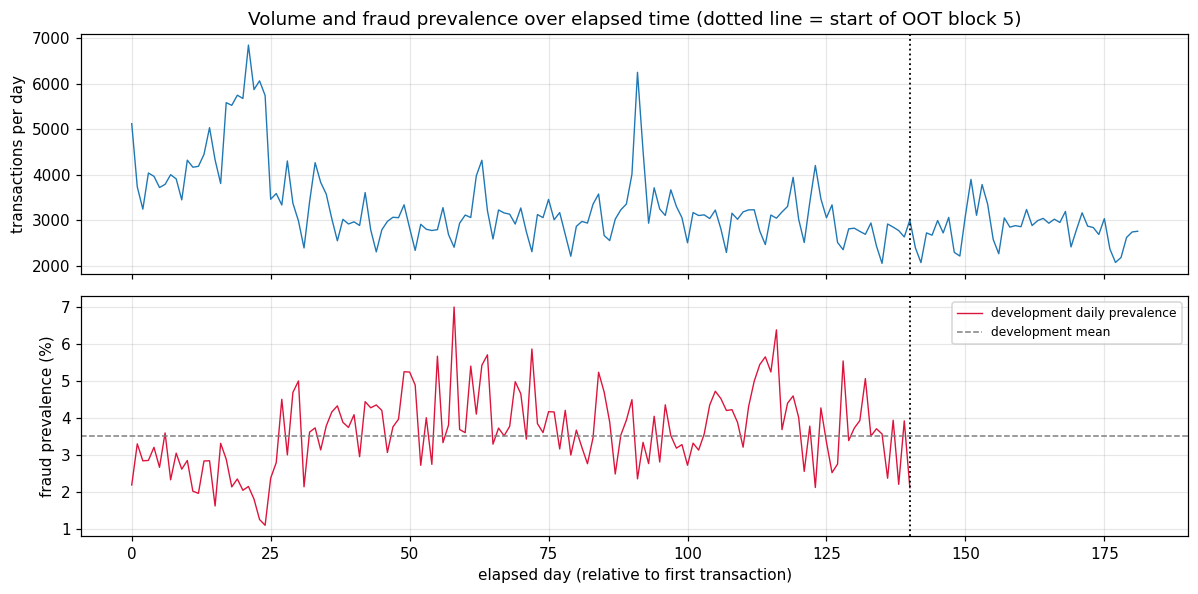

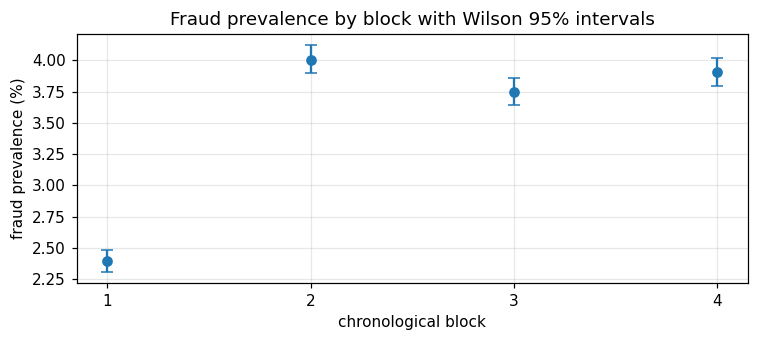

In [6]:
"""Section 4 - target prevalence over time and the deferred evaluation function."""


def wilson_interval(successes: int, n: int, z: float = 1.96) -> Tuple[float, float]:
    """Wilson score interval for a proportion; reliable at low prevalence.

    Args:
        successes: count of positives (>= 0).
        n: total trials (>= 0). Returns (nan, nan) when n == 0.
        z: normal quantile; 1.96 is the two-sided 95% interval.
    """
    if n < 0 or successes < 0 or successes > max(n, 0):
        raise ValueError(f"Invalid counts: successes={successes}, n={n}.")
    if n == 0:
        return (float("nan"), float("nan"))
    p = successes / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


def prevalence_by_block(frame: pd.DataFrame, target: str = TARGET_COLUMN,
                        block_column: str = "chrono_block",
                        oot_block: int = OOT_BLOCK) -> pd.DataFrame:
    """Per-block row count, positives, prevalence and a Wilson 95% interval."""
    if target not in frame.columns or block_column not in frame.columns:
        raise KeyError(f"prevalence_by_block requires '{target}' and '{block_column}'.")
    rows = []
    for block, sub in frame.groupby(block_column, sort=True)[target]:
        n, k = int(len(sub)), int(sub.sum())
        lo, hi = wilson_interval(k, n)
        rows.append({
            "block": int(block),
            "role": "OOT" if int(block) >= oot_block else "dev",
            "n": n,
            "missing_target": int(sub.isna().sum()),
            "positives": k,
            "prevalence_pct": round(100 * k / n, 4) if n else float("nan"),
            "ci_low_pct": round(100 * lo, 4),
            "ci_high_pct": round(100 * hi, 4),
        })
    return pd.DataFrame(rows)


def recall_at_fixed_fpr(y_true: Sequence[int], y_score: Sequence[float],
                        fpr: float = CONFIG["FIXED_FPR"]) -> Dict[str, Any]:
    """Recall at a fixed false-positive rate, with its denominators stated.

    The score threshold is the (1 - fpr) quantile of the NEGATIVE-class scores,
    so the realised FPR is as close to the target as the negative sample allows.

    This notebook produces no model, so this function is defined for the
    modelling stage and is NOT invoked on real data here. Calling it on absent
    predictions would fabricate a result; it therefore stays unused until a
    model exists. It is exercised only in the synthetic checks (Section 14).
    """
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score, dtype=float)
    if y_true.shape != y_score.shape:
        raise ValueError("y_true and y_score must have the same shape.")
    if not 0 < fpr < 1:
        raise ValueError(f"fpr must lie in (0, 1), got {fpr}.")
    neg, pos = y_score[y_true == 0], y_score[y_true == 1]
    if neg.size == 0 or pos.size == 0:
        raise ValueError("Both classes must be present to evaluate recall at a fixed FPR.")
    threshold = float(np.quantile(neg, 1 - fpr))
    flagged_neg = int((neg >= threshold).sum())
    flagged_pos = int((pos >= threshold).sum())
    return {
        "threshold": threshold,
        "target_fpr": fpr,
        "realised_fpr": flagged_neg / neg.size,
        "recall": flagged_pos / pos.size,
        "n_negatives": int(neg.size),
        "n_positives": int(pos.size),
        "denominator_note": ("recall denominator = positives in the evaluated block; "
                             "FPR denominator = negatives in the evaluated block"),
    }


PREVALENCE = prevalence_by_block(dev_df)
print(PREVALENCE.to_string(index=False))

_dev_prev = PREVALENCE[PREVALENCE.role == "dev"]
_table = np.array([_dev_prev["positives"].to_numpy(),
                   (_dev_prev["n"] - _dev_prev["positives"]).to_numpy()])
_chi2, _p, _, _ = stats.chi2_contingency(_table)
_cramers_v = float(np.sqrt(_chi2 / (_table.sum() * (min(_table.shape) - 1))))
PRIOR_SHIFT = {"chi2": float(_chi2), "p_value": float(_p), "cramers_v": _cramers_v,
               "blocks_compared": _dev_prev["block"].tolist()}
print(f"\nDev-block prevalence homogeneity: chi2={_chi2:,.1f}, p={_p:.3g}, "
      f"Cramer's V={_cramers_v:.4f} (effect size, not the p-value, is the "
      "quantity to judge at n>400k).")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)

_daily_volume = (
df.groupby("day_index")
.agg(n=(ID_COLUMN, "size"))
.reset_index()
)

_daily_dev_rate = (
dev_df.groupby("day_index")[TARGET_COLUMN]
.mean()
.reset_index(name="rate")
)

axes[0].plot(_daily_volume.day_index, _daily_volume.n, lw=0.9)
axes[0].set_ylabel("transactions per day")
axes[0].set_title("Volume and fraud prevalence over elapsed time "
                  f"(dotted line = start of OOT block {OOT_BLOCK})")
axes[1].plot(
    _daily_dev_rate.day_index,
    100 * _daily_dev_rate.rate,
    lw=0.9,
    color="crimson",
    label="development daily prevalence",
)
axes[1].axhline(100 * df.loc[DEV_MASK, TARGET_COLUMN].mean(), ls="--", c="grey",
                lw=1, label="development mean")
axes[1].set_ylabel("fraud prevalence (%)")
axes[1].set_xlabel("elapsed day (relative to first transaction)")
_oot_start_day = int(df.loc[~DEV_MASK, "day_index"].min())
for ax in axes:
    ax.axvline(_oot_start_day, color="black", ls=":", lw=1.2)
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(PREVALENCE.block, PREVALENCE.prevalence_pct,
            yerr=[PREVALENCE.prevalence_pct - PREVALENCE.ci_low_pct,
                  PREVALENCE.ci_high_pct - PREVALENCE.prevalence_pct],
            fmt="o", capsize=4)
ax.set_xticks(PREVALENCE.block)
ax.set_xlabel("chronological block")
ax.set_ylabel("fraud prevalence (%)")
ax.set_title("Fraud prevalence by block with Wilson 95% intervals")
plt.tight_layout()
plt.show()

### Interpreting Section 4 — prior shift and why thresholds are period-specific

If prevalence differs across blocks, a score threshold calibrated on one period
delivers a different alert volume and a different precision in the next, even
with an unchanged model. Two consequences follow, and both are protocol rather
than preference:

* an operating threshold must be **assessed per period**, not fixed once on the
  pooled development data;
* per-block **lift is computed against that block's own prevalence** (Section 5),
  so a prior shift cannot masquerade as feature signal.

Note the sample-size effect in the homogeneity test: at n > 400,000 an
inconsequential difference in prevalence produces an astronomically small
p-value. Cramér's V is the quantity to read.

**No model exists in this notebook, so no recall at 0.1% FPR is reported.**
`recall_at_fixed_fpr` is defined, documented and exercised on synthetic data in
Section 14, ready for the modelling stage. Reporting a number here would be
fabrication.

## 5. D-Series Temporal Risk Analysis

Five reusable diagnostics, applied to the numeric battery (amount, D-series,
C-series, distances, V-series):

* **PSI** with bin edges learned on the development reference block and reused
  unchanged for every comparison including OOT; a documented epsilon floor for
  empty bins; a separate MISSING bin; sample counts reported alongside.
* **Two-sample KS**, block 1 versus block 4 (both development), with statistic,
  p-value, both non-missing sample sizes and a Benjamini–Hochberg adjusted
  p-value.
* **Spearman** correlation with elapsed time.
* **Per-block top-decile fraud lift**, with the cut point learned on development
  data and lift taken against each block's own prevalence.
* **Lift stability**, defined explicitly as `1 − std(lift)/mean(lift)` over
  development blocks, withheld entirely when too few blocks carry enough
  positives.

The PSI bands (`< 0.10` stable, `0.10–0.25` moderate, `> 0.25` severe) are
**configured decision rules**, not universal laws, and PSI is a divergence, not
a hypothesis test — it has no p-value here and none is implied.

In [7]:
"""Section 5a - reusable drift, association and lift functions."""


def learn_psi_bins(reference: Sequence[float], bins: int = CONFIG["PSI_BINS"]) -> Optional[np.ndarray]:
    """Learn PSI bin edges from REFERENCE (development) values only.

    Quantile edges are de-duplicated, so a low-variance feature simply yields
    fewer bins rather than an error. Returns None when fewer than two distinct
    edges survive (a constant feature), which callers treat as "not assessable".
    """
    values = pd.Series(reference).dropna().to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return None
    edges = np.unique(np.quantile(values, np.linspace(0, 1, bins + 1)))
    if edges.size < 2:
        return None
    edges[0], edges[-1] = -np.inf, np.inf
    return edges


def calculate_psi(reference: Sequence[float], comparison: Sequence[float],
                  edges: Optional[np.ndarray] = None,
                  bins: int = CONFIG["PSI_BINS"],
                  epsilon: float = CONFIG["PSI_EPSILON"],
                  include_missing_bin: bool = True) -> Dict[str, Any]:
    """Population Stability Index of ``comparison`` against ``reference``.

    PSI = sum over bins of (p_comp - p_ref) * ln(p_comp / p_ref).

    Design decisions, all explicit:
      * Bin edges are learned from the reference sample only (or supplied by the
        caller, which is how development edges are reused for OOT).
      * Zero proportions are floored at ``epsilon`` (default 1e-6) before the
        logarithm, so an empty bin contributes a large-but-finite term instead
        of infinity. The floor is reported in the result.
      * When ``include_missing_bin``, missingness forms its own bin, so a
        feature that silently stops being populated registers as drift.

    PSI is a descriptive divergence, not a hypothesis test: it has no p-value
    and no null distribution here.

    Returns:
        dict with psi, n_reference, n_comparison, n_bins, bin_table,
        assessable and (when not assessable) reason.
    """
    ref = pd.Series(reference)
    cmp_ = pd.Series(comparison)
    ref_missing, cmp_missing = int(ref.isna().sum()), int(cmp_.isna().sum())
    ref_v = ref.dropna().to_numpy(dtype=float)
    cmp_v = cmp_.dropna().to_numpy(dtype=float)
    ref_v, cmp_v = ref_v[np.isfinite(ref_v)], cmp_v[np.isfinite(cmp_v)]

    if edges is None:
        edges = learn_psi_bins(ref_v, bins=bins)
    if edges is None or ref_v.size == 0 or cmp_v.size == 0:
        return {"psi": float("nan"), "assessable": False,
                "reason": "constant, empty or all-missing reference/comparison",
                "n_reference": int(ref_v.size), "n_comparison": int(cmp_v.size),
                "n_bins": 0, "epsilon": epsilon, "bin_table": None}

    ref_counts = np.histogram(ref_v, bins=edges)[0].astype(float)
    cmp_counts = np.histogram(cmp_v, bins=edges)[0].astype(float)
    labels = [f"({edges[i]:.6g}, {edges[i + 1]:.6g}]" for i in range(len(edges) - 1)]
    if include_missing_bin and (ref_missing or cmp_missing):
        ref_counts = np.append(ref_counts, ref_missing)
        cmp_counts = np.append(cmp_counts, cmp_missing)
        labels.append("MISSING")

    p_ref = np.clip(ref_counts / ref_counts.sum(), epsilon, None)
    p_cmp = np.clip(cmp_counts / cmp_counts.sum(), epsilon, None)
    contrib = (p_cmp - p_ref) * np.log(p_cmp / p_ref)
    return {
        "psi": float(contrib.sum()),
        "assessable": True,
        "reason": "",
        "n_reference": int(ref_counts.sum()),
        "n_comparison": int(cmp_counts.sum()),
        "n_bins": len(labels),
        "epsilon": epsilon,
        "bin_table": pd.DataFrame({"bin": labels, "p_reference": p_ref,
                                   "p_comparison": p_cmp, "contribution": contrib}),
    }


def classify_psi(psi: float,
                 moderate: float = CONFIG["PSI_MODERATE_THRESHOLD"],
                 severe: float = CONFIG["PSI_SEVERE_THRESHOLD"]) -> str:
    """Map a PSI value onto the CONFIGURED bands (not universal constants)."""
    if psi is None or not np.isfinite(psi):
        return "not_assessable"
    if psi < moderate:
        return "stable"
    if psi <= severe:
        return "moderate_drift"
    return "severe_drift"


def calculate_feature_psi_by_block(frame: pd.DataFrame, feature: str,
                                   reference_block: int, comparison_blocks: Sequence[int],
                                   block_column: str = "chrono_block",
                                   bins: int = CONFIG["PSI_BINS"]) -> pd.DataFrame:
    """PSI of each comparison block against a fixed reference block.

    Bin edges are learned once, on the reference block, and reused unchanged for
    every comparison block including OOT. That reuse is exactly what keeps the
    OOT transformation free of OOT-derived parameters.
    """
    if feature not in frame.columns:
        raise KeyError(f"Unknown feature '{feature}'.")
    ref_values = frame.loc[frame[block_column] == reference_block, feature]
    edges = learn_psi_bins(ref_values, bins=bins)
    rows = []
    for block in comparison_blocks:
        cmp_values = frame.loc[frame[block_column] == block, feature]
        result = calculate_psi(ref_values, cmp_values, edges=edges, bins=bins)
        rows.append({"feature": feature, "reference_block": reference_block,
                     "comparison_block": int(block), "psi": result["psi"],
                     "band": classify_psi(result["psi"]),
                     "n_reference": result["n_reference"],
                     "n_comparison": result["n_comparison"],
                     "assessable": result["assessable"]})
    return pd.DataFrame(rows)


def run_ks_tests(frame: pd.DataFrame, features: Sequence[str],
                 block_a: int, block_b: int,
                 block_column: str = "chrono_block",
                 min_n: int = CONFIG["MIN_NON_MISSING"]) -> pd.DataFrame:
    """Two-sample KS test of each feature between two blocks.

    Reports the statistic (an effect size on the CDF scale), the raw p-value and
    both non-missing sample sizes. At IEEE-CIS sample sizes a p-value near zero
    is expected for trivially small differences, so the statistic - not the
    p-value - carries the practical meaning.
    """
    a_frame = frame.loc[frame[block_column] == block_a]
    b_frame = frame.loc[frame[block_column] == block_b]
    rows = []
    for feature in features:
        a = a_frame[feature].dropna().to_numpy(dtype=float)
        b = b_frame[feature].dropna().to_numpy(dtype=float)
        a, b = a[np.isfinite(a)], b[np.isfinite(b)]
        if a.size < min_n or b.size < min_n:
            rows.append({"feature": feature, "ks_stat": np.nan, "ks_pvalue": np.nan,
                         "n_a": int(a.size), "n_b": int(b.size),
                         "assessable": False,
                         "reason": f"fewer than {min_n} non-missing values in a block"})
            continue
        result = stats.ks_2samp(a, b, method="asymp")
        rows.append({"feature": feature, "ks_stat": float(result.statistic),
                     "ks_pvalue": float(result.pvalue),
                     "n_a": int(a.size), "n_b": int(b.size),
                     "assessable": True, "reason": ""})
    return pd.DataFrame(rows)


def adjust_multiple_tests(pvalues: Sequence[float], alpha: float = CONFIG["KS_ALPHA"],
                          method: str = "benjamini_hochberg") -> pd.DataFrame:
    """Benjamini-Hochberg adjusted p-values and rejection flags.

    NaN p-values (tests that could not be run) are carried through as NaN and
    excluded from the multiplicity count, so unrunnable tests neither inflate
    nor deflate the correction.
    """
    if method != "benjamini_hochberg":
        raise ValueError(f"Unsupported correction '{method}'.")
    p = np.asarray(pvalues, dtype=float)
    out_adj = np.full(p.shape, np.nan)
    out_rej = np.zeros(p.shape, dtype=bool)
    valid = np.where(np.isfinite(p))[0]
    if valid.size:
        pv = p[valid]
        order = np.argsort(pv, kind="mergesort")
        ranked = pv[order]
        m = ranked.size
        adjusted = ranked * m / np.arange(1, m + 1)
        adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
        adjusted = np.clip(adjusted, 0, 1)
        restored = np.empty_like(adjusted)
        restored[order] = adjusted
        out_adj[valid] = restored
        out_rej[valid] = restored <= alpha
    return pd.DataFrame({"pvalue": p, "adjusted_pvalue": out_adj,
                         "reject": out_rej, "alpha": alpha, "method": method,
                         "n_tests": int(valid.size)})


def calculate_spearman_time_risk(frame: pd.DataFrame, features: Sequence[str],
                                 time_column: str = "elapsed_days",
                                 min_n: int = CONFIG["MIN_NON_MISSING"]) -> pd.DataFrame:
    """Spearman rank correlation between each feature and elapsed time.

    Spearman, not Pearson: temporal drift in these columns is monotone but not
    linear, and rank correlation is unaffected by the heavy right tails that
    dominate the V and D series.
    """
    rows = []
    time_values = frame[time_column]
    for feature in features:
        series = frame[feature]
        mask = series.notna() & np.isfinite(series.astype(float)) & time_values.notna()
        n = int(mask.sum())
        if n < min_n or series[mask].nunique() < 2:
            rows.append({"feature": feature, "spearman_corr_time": np.nan,
                         "spearman_pvalue": np.nan, "n": n, "assessable": False,
                         "reason": "insufficient non-missing values or constant"})
            continue
        result = stats.spearmanr(series[mask].to_numpy(dtype=float),
                                 time_values[mask].to_numpy(dtype=float))
        rows.append({"feature": feature,
                     "spearman_corr_time": float(result.statistic),
                     "spearman_pvalue": float(result.pvalue),
                     "n": n, "assessable": True, "reason": ""})
    return pd.DataFrame(rows)


def calculate_top_decile_lift(frame: pd.DataFrame, feature: str,
                              cut_point: float, target: str = TARGET_COLUMN,
                              min_positives: int = CONFIG["MIN_POSITIVES_FOR_LIFT"],
                              direction: str = "upper") -> Dict[str, Any]:
    """Fraud lift of the top decile of ``feature`` within one block.

    The cut point is supplied by the caller (learned on development data) so
    that OOT never defines its own boundary. Lift is computed against the
    prevalence of the SAME block, so a block-level prior shift cannot be
    mistaken for feature signal.

    Ties at the cut point are kept in the flagged group, and the realised
    flagged share is returned so a lumpy, low-variance feature is visible rather
    than silently mislabelled a "decile".
    """
    if direction not in {"upper", "lower"}:
        raise ValueError("direction must be 'upper' or 'lower'.")
    values, y = frame[feature], frame[target]
    mask = values.notna()
    n_valid = int(mask.sum())
    if n_valid == 0 or not np.isfinite(cut_point):
        return {"feature": feature, "lift": np.nan, "assessable": False,
                "reason": "no non-missing values or undefined cut point",
                "n_evaluated": n_valid, "n_flagged": 0, "positives_flagged": 0,
                "flagged_share": np.nan, "block_prevalence": np.nan}
    flagged = (values >= cut_point) if direction == "upper" else (values <= cut_point)
    flagged = flagged & mask
    n_flagged = int(flagged.sum())
    positives_flagged = int(y[flagged].sum())
    prevalence = float(y[mask].mean())
    if n_flagged == 0 or prevalence == 0:
        return {"feature": feature, "lift": np.nan, "assessable": False,
                "reason": "empty flagged group or zero prevalence",
                "n_evaluated": n_valid, "n_flagged": n_flagged,
                "positives_flagged": positives_flagged,
                "flagged_share": n_flagged / n_valid, "block_prevalence": prevalence}
    lift = (positives_flagged / n_flagged) / prevalence
    assessable = positives_flagged >= min_positives
    return {"feature": feature, "lift": float(lift), "assessable": assessable,
            "reason": "" if assessable else
                      f"only {positives_flagged} positives in the flagged group "
                      f"(< {min_positives}); lift is unreliable",
            "n_evaluated": n_valid, "n_flagged": n_flagged,
            "positives_flagged": positives_flagged,
            "flagged_share": n_flagged / n_valid, "block_prevalence": prevalence}


def calculate_lift_stability(lifts: Mapping[int, float],
                             min_blocks: int = CONFIG["LIFT_STABILITY_MIN_BLOCKS"]) -> Dict[str, Any]:
    """Summarise how consistent a feature's top-decile lift is across blocks.

    Definition used throughout this notebook:

        lift_stability = 1 - (std(lift) / mean(lift))       [clipped to [0, 1]]

    i.e. one minus the coefficient of variation of the per-block lift. 1.0 means
    identical lift in every block; 0.0 means the dispersion is as large as the
    mean. The metric is only returned when at least ``min_blocks`` blocks
    produced an assessable lift AND the mean lift is positive; otherwise the
    verdict is ``insufficient_evidence`` rather than a flattering number.
    """
    usable = {int(b): float(v) for b, v in lifts.items()
              if v is not None and np.isfinite(v)}
    if len(usable) < min_blocks:
        return {"lift_stability": None, "n_blocks": len(usable),
                "mean_lift": None, "std_lift": None, "direction": None,
                "verdict": "insufficient_evidence",
                "reason": f"assessable lift in only {len(usable)} block(s); "
                          f"{min_blocks} required"}
    values = np.array([usable[b] for b in sorted(usable)])
    mean, std = float(values.mean()), float(values.std(ddof=1))
    if mean <= 0:
        return {"lift_stability": None, "n_blocks": len(usable), "mean_lift": mean,
                "std_lift": std, "direction": None, "verdict": "insufficient_evidence",
                "reason": "non-positive mean lift; the ratio is undefined"}
    stability = float(np.clip(1 - std / mean, 0.0, 1.0))
    direction = "enriched" if mean > 1 else ("depleted" if mean < 1 else "neutral")
    return {"lift_stability": stability, "n_blocks": len(usable), "mean_lift": mean,
            "std_lift": std, "direction": direction,
            "verdict": "stable" if stability >= CONFIG["LIFT_STABILITY_THRESHOLD"] else "unstable", "reason": ""}


LOG.info("Drift, association and lift functions defined.")

09:12:29 | INFO    | Drift, association and lift functions defined.


09:12:30 | INFO    | Temporal-risk battery covers 371 numeric features.


Workload estimate: 371 features x (3 dev PSI comparisons + 1 dev->OOT PSI + 4 development lift evaluations) on 590,540 rows; float32 columns are read one at a time.


09:17:23 | INFO    | Wrote ./artifacts/feature_risk_table.csv (371 features x 32 columns).


  family               verdict  features
       C         moderate_risk         3
       C                stable         8
       C         temporal_risk         3
       D         moderate_risk         7
       D                stable         4
       D         temporal_risk         4
       V insufficient_evidence         1
       V         moderate_risk         2
       V                stable        80
       V         temporal_risk       256
  amount         moderate_risk         1
distance                stable         2

D-series detail (the family the source notebook flagged as range-expanding):
feature  development_non_missing_count  PSI_max_development_only  ks_stat  ks_adjusted_pvalue  spearman_corr_time  lift_stability  missingness_drift       verdict       action
     D1                         471496                  0.178495 0.162745        0.000000e+00            0.091844        0.739975           0.000838 moderate_risk      monitor
    D10                         40604

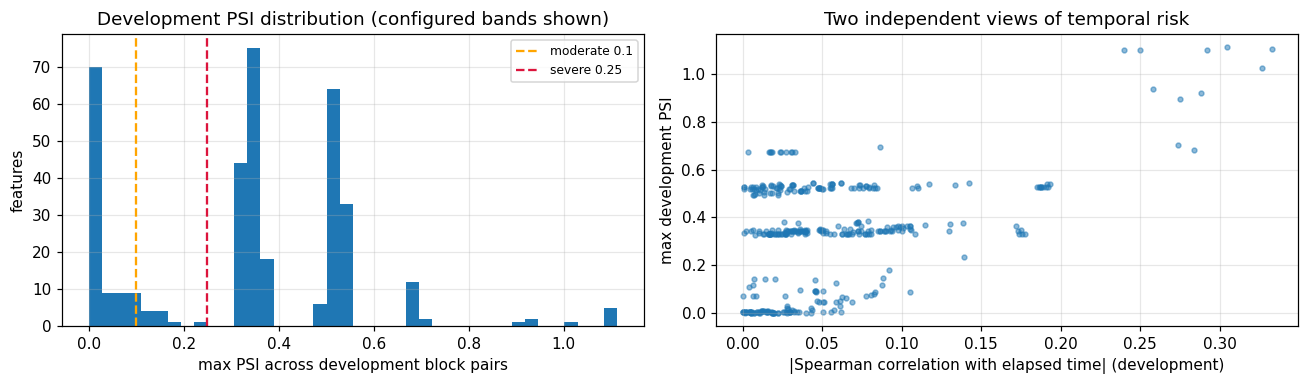

In [8]:
"""Section 5b - run the temporal-risk battery and build feature_risk_table.csv."""


def family_of(column: str) -> str:
    """Assign a column to its IEEE-CIS feature family (working interpretation)."""
    if column == "TransactionAmt":
        return "amount"
    if column == "ProductCD":
        return "product"
    if column.startswith("card"):
        return "entity"
    if column.startswith("addr"):
        return "entity"
    if column.endswith("emaildomain"):
        return "entity"
    if column in ("DeviceType", "DeviceInfo"):
        return "entity"
    if column.startswith("dist"):
        return "distance"
    if len(column) > 1 and column[0] == "C" and column[1:].isdigit():
        return "C"
    if len(column) > 1 and column[0] == "D" and column[1:].isdigit():
        return "D"
    if len(column) > 1 and column[0] == "M" and column[1:].isdigit():
        return "M"
    if len(column) > 1 and column[0] == "V" and column[1:].isdigit():
        return "V"
    if column.startswith("id_"):
        return "identity"
    return "other"


NUMERIC_FEATURES = [c for c in FEATURE_COLUMNS if df[c].dtype.kind in "if"]
C_SERIES = sorted([c for c in NUMERIC_FEATURES if family_of(c) == "C"],
                  key=lambda c: int(c[1:]))
# The audit battery: D-series (the temporal-risk family of interest), the
# amount, distances and counting features, plus every numeric V column. All
# statistics below are computed on development rows unless a cell says
# otherwise; OOT enters only as a *comparison* sample against dev-learned edges.
AUDIT_FEATURES = [c for c in (["TransactionAmt"] + D_SERIES + C_SERIES + V_SERIES
                              + [c for c in ("dist1", "dist2") if c in df.columns])
                  if c in NUMERIC_FEATURES]
AUDIT_FEATURES = sorted(set(AUDIT_FEATURES), key=AUDIT_FEATURES.index)
LOG.info("Temporal-risk battery covers %d numeric features.", len(AUDIT_FEATURES))

# --- estimated workload, printed before the expensive loop -------------------
print(f"Workload estimate: {len(AUDIT_FEATURES)} features x "
      f"({len(DEV_BLOCKS) - 1} dev PSI comparisons + 1 dev->OOT PSI + "
      f"{len(DEV_BLOCKS)} development lift evaluations) "
      f"on {len(df):,} rows; float32 columns are read one at a time.")

DEV_REFERENCE_BLOCK = DEV_BLOCKS[0]
_dev_view = AUDITOR.guard("psi_bin_edges_and_cut_points", dev_df[[ID_COLUMN]])

psi_records: List[Dict[str, Any]] = []
lift_records: List[Dict[str, Any]] = []
risk_rows: List[Dict[str, Any]] = []
PSI_EDGES: Dict[str, Optional[np.ndarray]] = {}
DECILE_CUT_POINTS: Dict[str, float] = {}

for feature in AUDIT_FEATURES:
    dev_values = dev_df[feature]
    oot_values = oot_df[feature]

    # ---- development-only fitted objects: bin edges and the decile cut point
    edges = learn_psi_bins(dev_df.loc[dev_df["chrono_block"] == DEV_REFERENCE_BLOCK, feature])
    PSI_EDGES[feature] = edges
    finite_dev = dev_values[pd.to_numeric(dev_values, errors="coerce").map(np.isfinite)]
    cut_point = (float(np.quantile(finite_dev, CONFIG["TOP_DECILE_QUANTILE"]))
                 if len(finite_dev) >= CONFIG["MIN_NON_MISSING"] else float("nan"))
    DECILE_CUT_POINTS[feature] = cut_point
    reference_mask = dev_df["chrono_block"] == DEV_REFERENCE_BLOCK
    reference_ids = dev_df.loc[reference_mask, ID_COLUMN].to_numpy()
    AUDITOR.register_fit(f"psi_edges::{feature}", "bin_edges",
                         reference_ids, [DEV_REFERENCE_BLOCK])
    AUDITOR.register_fit(f"decile_cut::{feature}", "threshold",
                         dev_df[ID_COLUMN].to_numpy(), DEV_BLOCKS)

    # ---- PSI: dev reference block vs later dev blocks, then dev vs OOT -------
    psi_pairs: Dict[str, float] = {}
    for block in DEV_BLOCKS[1:]:
        res = calculate_psi(dev_df.loc[dev_df["chrono_block"] == DEV_REFERENCE_BLOCK, feature],
                            dev_df.loc[dev_df["chrono_block"] == block, feature],
                            edges=edges)
        psi_pairs[f"block{DEV_REFERENCE_BLOCK}_vs_block{block}"] = res["psi"]
        psi_records.append({"feature": feature,
                            "pair": f"block{DEV_REFERENCE_BLOCK}_vs_block{block}",
                            "psi": res["psi"], "n_reference": res["n_reference"],
                            "n_comparison": res["n_comparison"],
                            "scope": "development"})
    res_oot = calculate_psi(dev_values, oot_values, edges=edges)
    psi_pairs[f"dev_vs_block{OOT_BLOCK}"] = res_oot["psi"]
    psi_records.append({"feature": feature, "pair": f"dev_vs_block{OOT_BLOCK}",
                        "psi": res_oot["psi"], "n_reference": res_oot["n_reference"],
                        "n_comparison": res_oot["n_comparison"],
                        "scope": "oot_evaluation_only"})

    finite_psi = {k: v for k, v in psi_pairs.items() if np.isfinite(v)}
    dev_finite_psi = {
        k: v for k, v in finite_psi.items()
        if not k.startswith("dev_vs_block")
    }
    # Decision summaries are development-only. OOT PSI remains a separate
    # evaluation diagnostic and cannot become the maximum or worst pair.
    psi_max = max(dev_finite_psi.values()) if dev_finite_psi else np.nan
    psi_mean = (float(np.mean(list(dev_finite_psi.values())))
                if dev_finite_psi else np.nan)
    worst_pair = (max(dev_finite_psi, key=dev_finite_psi.get)
                  if dev_finite_psi else "")
    psi_max_dev = psi_max

    # ---- per-block top-decile lift, using the development cut point ---------
    block_lifts: Dict[int, float] = {}
    for block in DEV_BLOCKS:
        block_frame = dev_df.loc[
            dev_df["chrono_block"] == block,
            [feature, TARGET_COLUMN],
        ]
        result = calculate_top_decile_lift(block_frame, feature, cut_point)
        lift_records.append({
            "feature": feature,
            "block": block,
            **{k: v for k, v in result.items() if k != "feature"},
        })
        if result["assessable"]:
            block_lifts[block] = result["lift"]
    
    dev_lifts = block_lifts
    stability = calculate_lift_stability(dev_lifts)

    # ---- missingness drift: dev vs OOT missing-rate difference --------------
    dev_missing = float(dev_values.isna().mean())
    oot_missing = float(oot_values.isna().mean())

    risk_rows.append({
        "feature": feature,
        "family": family_of(feature),
        "development_non_missing_count": int(dev_values.notna().sum()),
        "oot_non_missing_count": int(oot_values.notna().sum()),
        "PSI_max": psi_max,
        "PSI_max_development_only": psi_max_dev,
        "PSI_mean": psi_mean,
        "PSI_worst_block_pair": worst_pair,
        "PSI_band_development_only": classify_psi(psi_max_dev),
        "PSI_dev_vs_oot": psi_pairs.get(f"dev_vs_block{OOT_BLOCK}", np.nan),
        "lift_by_block": json.dumps({str(k): round(v, 4) for k, v in sorted(block_lifts.items())}),
        "lift_stability": stability["lift_stability"],
        "lift_stability_blocks": stability["n_blocks"],
        "lift_mean_development": stability["mean_lift"],
        "lift_direction": stability["direction"],
        "development_missing_rate": round(dev_missing, 6),
        "oot_missing_rate": round(oot_missing, 6),
        "missingness_drift": round(oot_missing - dev_missing, 6),
    })

PSI_LONG = pd.DataFrame(psi_records)
LIFT_LONG = pd.DataFrame(lift_records)
feature_risk = pd.DataFrame(risk_rows)

# --- KS: block 1 vs block 4, both development, with BH correction ------------
ks_table = run_ks_tests(dev_df, AUDIT_FEATURES, block_a=DEV_BLOCKS[0], block_b=DEV_BLOCKS[-1])
ks_adjusted = adjust_multiple_tests(ks_table["ks_pvalue"].to_numpy())
ks_table["ks_adjusted_pvalue"] = ks_adjusted["adjusted_pvalue"].to_numpy()
ks_table["ks_reject_bh"] = ks_adjusted["reject"].to_numpy()
AUDITOR.register_fit("ks_block1_vs_block4", "hypothesis_test",
                     dev_df[ID_COLUMN].to_numpy(), DEV_BLOCKS)

# --- Spearman association with elapsed time, development rows only -----------
spearman_table = calculate_spearman_time_risk(dev_df, AUDIT_FEATURES)
spearman_adjusted = adjust_multiple_tests(spearman_table["spearman_pvalue"].to_numpy())
spearman_table["spearman_adjusted_pvalue"] = spearman_adjusted["adjusted_pvalue"].to_numpy()
AUDITOR.register_fit("spearman_time_risk", "association_score",
                     dev_df[ID_COLUMN].to_numpy(), DEV_BLOCKS)

feature_risk = (feature_risk
                .merge(ks_table.rename(columns={"n_a": "ks_n_block1", "n_b": "ks_n_block4"})
                       [["feature", "ks_stat", "ks_pvalue", "ks_adjusted_pvalue",
                         "ks_reject_bh", "ks_n_block1", "ks_n_block4"]],
                       on="feature", how="left")
                .merge(spearman_table[["feature", "spearman_corr_time", "spearman_pvalue",
                                       "spearman_adjusted_pvalue", "n"]]
                       .rename(columns={"n": "spearman_n"}),
                       on="feature", how="left"))


def assign_verdict(row: pd.Series, spearman_cut: float) -> Tuple[str, str, str]:
    """Map development-only evidence onto (verdict, action, reason).

    Only development evidence is consulted: PSI within development blocks, the
    dev-only KS comparison, the dev Spearman association and dev lift
    stability. The dev-vs-OOT PSI column exists for *reporting* and is
    deliberately not read here.
    """
    reasons: List[str] = []
    psi_dev = row["PSI_max_development_only"]
    if not np.isfinite(psi_dev) and not np.isfinite(row["ks_stat"]):
        return ("insufficient_evidence", "investigate",
                "neither PSI nor KS was assessable (constant, empty or too sparse "
                f"in a block; dev non-missing = {row['development_non_missing_count']:,})")

    band = classify_psi(psi_dev)
    if band == "severe_drift":
        reasons.append(f"dev PSI_max {psi_dev:.3f} > {CONFIG['PSI_SEVERE_THRESHOLD']} "
                       f"(worst pair {row['PSI_worst_block_pair']})")
    elif band == "moderate_drift":
        reasons.append(f"dev PSI_max {psi_dev:.3f} in the configured moderate band")

    strong_time = np.isfinite(row["spearman_corr_time"]) and abs(row["spearman_corr_time"]) >= spearman_cut
    if strong_time:
        reasons.append(f"|Spearman(feature, elapsed time)| = "
                       f"{abs(row['spearman_corr_time']):.3f} >= {spearman_cut:.3f} "
                       f"(BH-adjusted p = {row['spearman_adjusted_pvalue']:.3g})")

    unstable_lift = (row["lift_stability"] is not None
                     and np.isfinite(row["lift_stability"] if row["lift_stability"] is not None else np.nan)
                     and row["lift_stability"] < CONFIG["LIFT_STABILITY_THRESHOLD"])
    if unstable_lift:
        reasons.append(f"top-decile lift stability {row['lift_stability']:.2f} < "
                       f"{CONFIG['LIFT_STABILITY_THRESHOLD']:.2f} "
                       f"across {int(row['lift_stability_blocks'])} dev blocks")
    if row["lift_stability"] is None:
        reasons.append("lift stability not estimable (too few blocks with enough positives)")


    if band == "severe_drift" or (strong_time and unstable_lift):
        return ("temporal_risk", "tag_not_drop", "; ".join(reasons))
    if band == "moderate_drift" or strong_time or unstable_lift:
        return ("moderate_risk", "monitor", "; ".join(reasons))
    if not np.isfinite(psi_dev):
        return (
            "insufficient_evidence",
            "investigate",
            "development PSI is unassessable and no configured non-PSI risk rule triggered",
        )
    return ("stable", "keep",
            f"dev PSI_max {psi_dev:.3f} below {CONFIG['PSI_MODERATE_THRESHOLD']}, "
            f"|Spearman| {abs(row['spearman_corr_time']):.3f} below {spearman_cut:.3f}"
            if np.isfinite(row["spearman_corr_time"])
            else f"dev PSI_max {psi_dev:.3f} below {CONFIG['PSI_MODERATE_THRESHOLD']}; "
                 "time correlation unassessable")


_verdicts = feature_risk.apply(
    lambda r: assign_verdict(r, CONFIG["SPEARMAN_RISK_THRESHOLD"]), axis=1)
feature_risk["verdict"] = [v[0] for v in _verdicts]
feature_risk["action"] = [v[1] for v in _verdicts]
feature_risk["reason"] = [v[2] for v in _verdicts]
feature_risk["decision_scope"] = "development_only"

feature_risk = feature_risk.sort_values(["family", "feature"], kind="mergesort").reset_index(drop=True)
FEATURE_RISK_PATH = os.path.join(OUTPUT_DIRECTORY, "feature_risk_table.csv")
feature_risk.to_csv(FEATURE_RISK_PATH, index=False)
LOG.info("Wrote %s (%d features x %d columns).", FEATURE_RISK_PATH, *feature_risk.shape)

print(feature_risk.groupby(["family", "verdict"]).size().rename("features").reset_index().to_string(index=False))
print("\nD-series detail (the family the source notebook flagged as range-expanding):")
_d_view = feature_risk[feature_risk.family == "D"][
    ["feature", "development_non_missing_count", "PSI_max_development_only",
     "ks_stat", "ks_adjusted_pvalue", "spearman_corr_time", "lift_stability",
     "missingness_drift", "verdict", "action"]]
print(_d_view.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
_plot = feature_risk.dropna(subset=["PSI_max_development_only"])
axes[0].hist(_plot["PSI_max_development_only"], bins=40)
axes[0].axvline(CONFIG["PSI_MODERATE_THRESHOLD"], color="orange", ls="--",
                label=f"moderate {CONFIG['PSI_MODERATE_THRESHOLD']}")
axes[0].axvline(CONFIG["PSI_SEVERE_THRESHOLD"], color="crimson", ls="--",
                label=f"severe {CONFIG['PSI_SEVERE_THRESHOLD']}")
axes[0].set_xlabel("max PSI across development block pairs")
axes[0].set_ylabel("features")
axes[0].set_title("Development PSI distribution (configured bands shown)")
axes[0].legend(fontsize=8)
axes[1].scatter(feature_risk["spearman_corr_time"].abs(),
                feature_risk["PSI_max_development_only"], s=10, alpha=0.5)
axes[1].set_xlabel("|Spearman correlation with elapsed time| (development)")
axes[1].set_ylabel("max development PSI")
axes[1].set_title("Two independent views of temporal risk")
plt.tight_layout()
plt.show()

### Interpreting Section 5

Three points a reader should hold onto:

1. **The verdict rule reads development evidence only.** `PSI_dev_vs_oot` is
   computed and exported because RQ7 asks about OOT generalization risk, but
   `assign_verdict` never reads it. That separation is the difference between
   *reporting* on the holdout and *deciding* with it.
2. **A tiny KS p-value is not a finding.** With ~120,000 rows per block, KS
   detects differences far below anything that would change a model's behaviour.
   The statistic (a maximum CDF gap) is the effect size; the adjusted p-value
   only says the gap is not sampling noise.
3. **Lift stability is withheld, not defaulted.** A feature whose top decile
   contains fewer than the configured minimum positives returns
   `insufficient_evidence`, which propagates into the ledger as `null` rather
   than as a flattering number.

## 6. Missingness Stability and Confounding

Columns blank on exactly the same rows are collapsed into one **missingness
pattern** before testing. Without this, a single underlying event — most often
"the identity table had no matching row" — is counted once per column, inflating
both the discovery count and the multiplicity correction.

Each pattern then gets: a missing rate by block, fraud rates for the missing and
observed groups by block with their positive counts, a ProductCD-stratified
repeat of the same contrast, a chi-square test with BH correction, a
direction-consistency requirement across development blocks, and an explicit
check for sign reversal inside strata.

09:17:26 | INFO    | 339 partially-missing columns collapse to 65 distinct missingness patterns.


Patterns tested: 65 of 65; surviving BH + effect size + direction consistency: 27.
Patterns whose aggregate direction reverses inside at least one reliable ProductCD stratum: 32. A reversal is a Simpson-type warning: the aggregate association is at least partly a product-mix effect. This is an association, not evidence that blankness causes fraud.

Top patterns by |effect size|:
 pattern_lead  n_columns  n_blank  n_filled  delta_pp    phi  adjusted_pvalue  direction_consistency  keep_indicator
           D7          1   442488     29944   -12.230 0.1618              0.0                    1.0           False
        addr1          2    53761    418671     8.898 0.1534              0.0                    1.0            True
          D14          1   422596     49836    -8.885 0.1482              0.0                    1.0           False
          D12          1   419729     52703    -8.844 0.1512              0.0                    1.0            True
          D13          1   423459

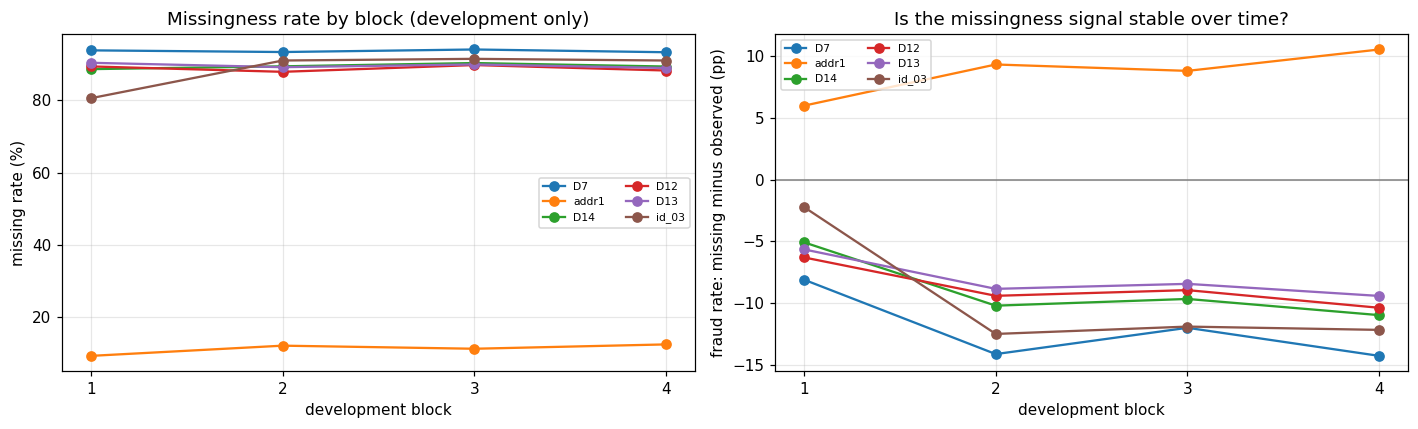

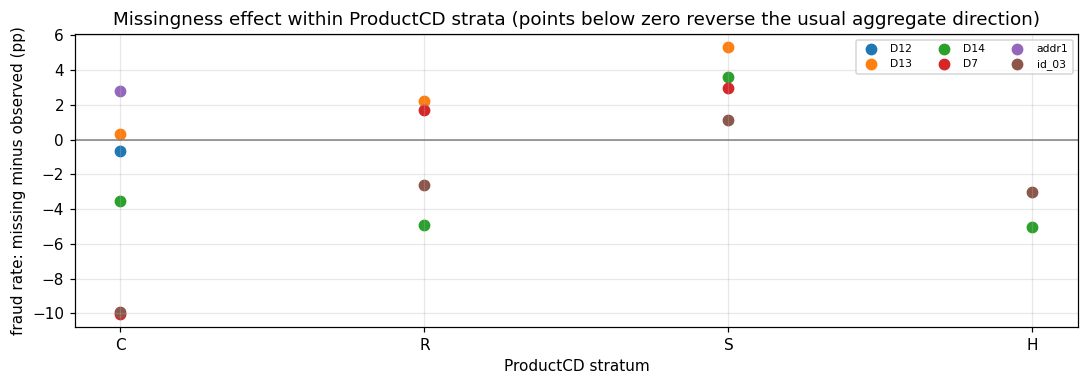

In [9]:
"""Section 6 - missingness stability, ProductCD stratification and confounding."""


def analyze_missingness_by_block(frame: pd.DataFrame, features: Sequence[str],
                                 target: str = TARGET_COLUMN,
                                 block_column: str = "chrono_block",
                                 min_group_n: int = CONFIG["MIN_GROUP_N"]) -> pd.DataFrame:
    """Missing rate and fraud rate for the missing vs observed group, per block.

    Every returned rate carries its own denominator (``n_missing`` /
    ``n_observed``) so no percentage in the output is unattributable. Groups
    smaller than ``min_group_n`` are reported with ``reliable = False`` rather
    than dropped, because their absence would itself be informative.
    """
    if not features:
        raise ValueError("analyze_missingness_by_block requires at least one feature.")
    rows = []
    for feature in features:
        indicator = frame[feature].isna()
        for block, idx in frame.groupby(block_column).groups.items():
            sub_missing = indicator.loc[idx]
            y = frame.loc[idx, target]
            n_missing, n_observed = int(sub_missing.sum()), int((~sub_missing).sum())
            rows.append({
                "feature": feature, "block": int(block),
                "n": len(idx), "n_missing": n_missing, "n_observed": n_observed,
                "missing_rate": n_missing / len(idx) if len(idx) else np.nan,
                "positives_missing": int(y[sub_missing].sum()),
                "positives_observed": int(y[~sub_missing].sum()),
                "fraud_rate_missing": float(y[sub_missing].mean()) if n_missing else np.nan,
                "fraud_rate_observed": float(y[~sub_missing].mean()) if n_observed else np.nan,
                "reliable": min(n_missing, n_observed) >= min_group_n,
            })
    out = pd.DataFrame(rows)
    out["delta_pp"] = 100 * (out["fraud_rate_missing"] - out["fraud_rate_observed"])
    return out


def analyze_missingness_by_product(frame: pd.DataFrame, features: Sequence[str],
                                   product_column: str = "ProductCD",
                                   target: str = TARGET_COLUMN,
                                   min_group_n: int = CONFIG["MIN_GROUP_N"]) -> pd.DataFrame:
    """Same contrast as ``analyze_missingness_by_block`` but stratified by product.

    The aggregate "missing implies more/less fraud" relationship can invert
    inside a stratum when ProductCD drives both the missingness and the fraud
    rate. This function produces the per-stratum evidence needed to check that,
    and the caller compares the signs.
    """
    if product_column not in frame.columns:
        raise KeyError(f"'{product_column}' is not present; stratified analysis "
                       "cannot run and must be recorded as not computed.")
    rows = []
    for feature in features:
        indicator = frame[feature].isna()
        for product, idx in frame.groupby(product_column, observed=True).groups.items():
            sub_missing = indicator.loc[idx]
            y = frame.loc[idx, target]
            n_missing, n_observed = int(sub_missing.sum()), int((~sub_missing).sum())
            rows.append({
                "feature": feature, "product": product, "n": len(idx),
                "n_missing": n_missing, "n_observed": n_observed,
                "positives_missing": int(y[sub_missing].sum()),
                "positives_observed": int(y[~sub_missing].sum()),
                "fraud_rate_missing": float(y[sub_missing].mean()) if n_missing else np.nan,
                "fraud_rate_observed": float(y[~sub_missing].mean()) if n_observed else np.nan,
                "reliable": min(n_missing, n_observed) >= min_group_n,
            })
    out = pd.DataFrame(rows)
    out["delta_pp"] = 100 * (out["fraud_rate_missing"] - out["fraud_rate_observed"])
    return out


def group_by_missingness_pattern(frame: pd.DataFrame, features: Sequence[str]) -> Dict[str, List[str]]:
    """Collapse columns that are blank on exactly the same rows into one pattern.

    Testing each column separately would count one underlying signal (for
    example "the identity table had no matching row") once per column and
    inflate both the discovery count and the multiplicity correction. Hashing
    the boolean missing-mask is O(n) per column instead of O(n) per pair.
    Representative = the first column in deterministic sorted order.
    """
    buckets: Dict[Any, List[str]] = {}
    for column in features:
        key = hashlib.sha1(frame[column].isna().to_numpy().tobytes()).hexdigest()
        buckets.setdefault(key, []).append(column)
    return {sorted(members)[0]: sorted(members) for members in buckets.values()}


# --- candidate features: those with genuinely partial missingness in dev -----
_missing_rate_dev = dev_df[FEATURE_COLUMNS].isna().mean()
MISSINGNESS_CANDIDATES = sorted(_missing_rate_dev[(_missing_rate_dev > CONFIG["PARTIAL_MISSING_MIN_RATE"])
                                                  & (_missing_rate_dev < CONFIG["PARTIAL_MISSING_MAX_RATE"])].index)
PATTERN_GROUPS = group_by_missingness_pattern(dev_df, MISSINGNESS_CANDIDATES)
PATTERN_LEADS = sorted(PATTERN_GROUPS)
LOG.info("%d partially-missing columns collapse to %d distinct missingness patterns.",
         len(MISSINGNESS_CANDIDATES), len(PATTERN_LEADS))

AUDITOR.guard("missingness_pattern_tests", dev_df[[ID_COLUMN]])
MISSING_BY_BLOCK = analyze_missingness_by_block(dev_df, PATTERN_LEADS)
MISSING_BY_PRODUCT = analyze_missingness_by_product(dev_df, PATTERN_LEADS)

# --- one chi-square test per PATTERN, on development rows, BH-corrected -----
_rows = []
_y_dev = dev_df[TARGET_COLUMN]
for lead in PATTERN_LEADS:
    blank = dev_df[lead].isna()
    n_blank, n_filled = int(blank.sum()), int((~blank).sum())
    if min(n_blank, n_filled) < CONFIG["MIN_GROUP_N"]:
        _rows.append({"pattern_lead": lead, "n_columns": len(PATTERN_GROUPS[lead]),
                      "n_blank": n_blank, "n_filled": n_filled, "delta_pp": np.nan,
                      "phi": np.nan, "pvalue": np.nan, "tested": False,
                      "reason": f"a group has fewer than {CONFIG['MIN_GROUP_N']} rows"})
        continue
    k_blank, k_filled = int(_y_dev[blank].sum()), int(_y_dev[~blank].sum())
    table = np.array([[k_blank, n_blank - k_blank], [k_filled, n_filled - k_filled]])
    chi2, pvalue, _, _ = stats.chi2_contingency(table)
    delta_pp = 100 * (k_blank / n_blank - k_filled / n_filled)
    # Per-block sign consistency within development.
    signs = []
    for block in DEV_BLOCKS:
        m = dev_df["chrono_block"] == block
        if (blank & m).sum() >= CONFIG["MIN_BLOCK_GROUP_N"] and ((~blank) & m).sum() >= CONFIG["MIN_BLOCK_GROUP_N"]:
            signs.append(np.sign(_y_dev[blank & m].mean() - _y_dev[(~blank) & m].mean()))
    consistency = float(np.mean(np.array(signs) == np.sign(delta_pp))) if signs else np.nan
    _rows.append({"pattern_lead": lead, "n_columns": len(PATTERN_GROUPS[lead]),
                  "n_blank": n_blank, "n_filled": n_filled,
                  "delta_pp": round(delta_pp, 3),
                  "phi": round(float(np.sqrt(chi2 / len(_y_dev))), 4),
                  "pvalue": float(pvalue), "direction_consistency": consistency,
                  "tested": True, "reason": ""})

MISSINGNESS_TESTS = pd.DataFrame(_rows)
_adj = adjust_multiple_tests(MISSINGNESS_TESTS["pvalue"].to_numpy())
MISSINGNESS_TESTS["adjusted_pvalue"] = _adj["adjusted_pvalue"].to_numpy()
MISSINGNESS_TESTS["reject_bh"] = _adj["reject"].to_numpy()
MISSINGNESS_TESTS["keep_indicator"] = (
    MISSINGNESS_TESTS["reject_bh"]
    & (MISSINGNESS_TESTS["delta_pp"].abs() >= CONFIG["MIN_ABS_DELTA_PP"])
    & (MISSINGNESS_TESTS["direction_consistency"] >= 0.75)
)

# --- Simpson / confounding check against ProductCD --------------------------
_conf_rows = []
for lead in PATTERN_LEADS:
    aggregate = MISSINGNESS_TESTS.loc[MISSINGNESS_TESTS.pattern_lead == lead, "delta_pp"]
    if aggregate.empty or not np.isfinite(aggregate.iloc[0]):
        continue
    agg_sign = np.sign(aggregate.iloc[0])
    strata = MISSING_BY_PRODUCT[(MISSING_BY_PRODUCT.feature == lead)
                                & MISSING_BY_PRODUCT.reliable
                                & MISSING_BY_PRODUCT.delta_pp.notna()]
    if strata.empty:
        _conf_rows.append({"pattern_lead": lead, "n_reliable_strata": 0,
                           "share_agreeing": np.nan, "flag": "no_reliable_strata"})
        continue
    agree = float((np.sign(strata.delta_pp) == agg_sign).mean())
    _conf_rows.append({
        "pattern_lead": lead, "n_reliable_strata": int(len(strata)),
        "share_agreeing": round(agree, 3),
        "flag": ("sign_reverses_in_some_strata" if agree < 1.0 else "consistent"),
    })
CONFOUNDING = pd.DataFrame(_conf_rows)
_reversal_by_lead = (CONFOUNDING.set_index("pattern_lead")["flag"].to_dict()
                     if len(CONFOUNDING) else {})
MISSINGNESS_TESTS["productcd_reversal_flag"] = MISSINGNESS_TESTS["pattern_lead"].map(
    lambda lead: _reversal_by_lead.get(lead, "not_assessed")
)
MISSINGNESS_TESTS["keep_indicator_pre_reversal"] = MISSINGNESS_TESTS["keep_indicator"]
MISSINGNESS_TESTS["keep_indicator"] = (
    MISSINGNESS_TESTS["keep_indicator_pre_reversal"]
    & MISSINGNESS_TESTS["productcd_reversal_flag"].eq("consistent")
)
MISSINGNESS_TESTS["indicator_action"] = np.where(
    MISSINGNESS_TESTS["keep_indicator"],
    "keep_indicator",
    np.where(
        MISSINGNESS_TESTS["keep_indicator_pre_reversal"]
        & MISSINGNESS_TESTS["productcd_reversal_flag"].ne("consistent"),
        "investigate_product_mix",
        "do_not_keep",
    ),
)

_reversals = CONFOUNDING[CONFOUNDING.flag == "sign_reverses_in_some_strata"]
print(f"Patterns tested: {int(MISSINGNESS_TESTS.tested.sum())} of {len(MISSINGNESS_TESTS)}; "
      f"surviving BH + effect size + direction consistency: "
      f"{int(MISSINGNESS_TESTS.keep_indicator.sum())}.")
print(f"Patterns whose aggregate direction reverses inside at least one reliable "
      f"ProductCD stratum: {len(_reversals)}. A reversal is a Simpson-type warning: "
      "the aggregate association is at least partly a product-mix effect. This is an "
      "association, not evidence that blankness causes fraud.")
print("\nTop patterns by |effect size|:")
print(MISSINGNESS_TESTS.reindex(MISSINGNESS_TESTS.delta_pp.abs().sort_values(ascending=False).index)
      .head(12)[["pattern_lead", "n_columns", "n_blank", "n_filled", "delta_pp",
                 "phi", "adjusted_pvalue", "direction_consistency", "keep_indicator"]]
      .to_string(index=False))

_top = (MISSINGNESS_TESTS.reindex(MISSINGNESS_TESTS.delta_pp.abs()
                                  .sort_values(ascending=False).index)
        .head(6)["pattern_lead"].tolist())
if _top:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for lead in _top:
        series = MISSING_BY_BLOCK[MISSING_BY_BLOCK.feature == lead]
        axes[0].plot(series.block, 100 * series.missing_rate, marker="o", label=lead)
        axes[1].plot(series.block, series.delta_pp, marker="o", label=lead)
    axes[0].set_xlabel("development block")
    axes[0].set_ylabel("missing rate (%)")
    axes[0].set_title("Missingness rate by block (development only)")
    axes[1].axhline(0, color="grey", lw=1)
    axes[1].set_xlabel("development block")
    axes[1].set_ylabel("fraud rate: missing minus observed (pp)")
    axes[1].set_title("Is the missingness signal stable over time?")
    for ax in axes:
        ax.set_xticks(DEV_BLOCKS)
        ax.legend(fontsize=7, ncol=2)
    plt.tight_layout()
    plt.show()

    _strata = MISSING_BY_PRODUCT[MISSING_BY_PRODUCT.feature.isin(_top)
                                 & MISSING_BY_PRODUCT.reliable]
    if not _strata.empty:
        fig, ax = plt.subplots(figsize=(10, 3.6))
        for lead, part in _strata.groupby("feature"):
            ax.scatter(part["product"].astype(str), part.delta_pp, label=lead, s=45)
        ax.axhline(0, color="grey", lw=1)
        ax.set_xlabel("ProductCD stratum")
        ax.set_ylabel("fraud rate: missing minus observed (pp)")
        ax.set_title("Missingness effect within ProductCD strata "
                     "(points below zero reverse the usual aggregate direction)")
        ax.legend(fontsize=7, ncol=3)
        plt.tight_layout()
        plt.show()

### Interpreting Section 6

A **sign reversal inside a ProductCD stratum is a Simpson-type warning**: the
aggregate contrast is at least partly a product-mix effect, because ProductCD
drives both the availability of the field and the base fraud rate. The
stratified panel is what separates the two; the aggregate number alone cannot.

A negative gap — blank implies *less* fraud — is usually the join, not the
customer. Before any such indicator is carried into a model it must be checked
against the identity-table coverage, because "no identity record existed" is a
data-collection fact, not a behavioural one.

Nothing in this section supports a causal reading. Missingness is associated with
the outcome; that is the entire claim.

## 7. V-Series Redundancy and Stability

Development data only, in eight deterministic steps: per-block Spearman
correlation → distance `1 − |ρ|` → average-linkage hierarchical clustering →
cross-block co-membership → retain only clusters stable across development blocks
→ pick one representative per stable cluster by mutual information with the
target on development rows → deterministic tie-breaking (MI, then completeness,
then name) → record why each representative won.

**Approximation, labelled as such:** each block's correlation matrix is estimated
on an evenly-spaced sample of that block when it exceeds the configured row
budget. Evenly spaced rather than random keeps the within-block chronology and
keeps the result reproducible without a seed. The sampling note is printed per
block and stored with the run.

No reducer is fitted. Deciding what *could* be reduced is EDA; performing the
reduction is modelling, and a reducer fitted here would have to be refitted
inside each training fold anyway to stay leakage-safe.

Workload estimate: 339 V columns x 4 development blocks; each block correlates a 339x339 Spearman matrix on at most 60,000 rows (~1 MB per matrix, one at a time).


09:19:30 | INFO    | Block 1: 338 features clustered into 143 clusters (evenly spaced deterministic sample of the block (60,000 of 118,108 rows); APPROXIMATION).
09:20:57 | INFO    | Block 2: 337 features clustered into 159 clusters (evenly spaced deterministic sample of the block (60,000 of 118,108 rows); APPROXIMATION).
09:22:22 | INFO    | Block 3: 336 features clustered into 153 clusters (evenly spaced deterministic sample of the block (60,000 of 118,108 rows); APPROXIMATION).
09:24:01 | INFO    | Block 4: 339 features clustered into 156 clusters (evenly spaced deterministic sample of the block (60,000 of 118,108 rows); APPROXIMATION).



Usable V columns: 339 (excluded as too sparse: 0).
Clusters judged stable across all 4 development blocks (co-membership >= 0.75): 119.
Columns inside a stable multi-member cluster: 172; representatives kept: 119.

Largest stable clusters:
 cluster_id feature  cluster_size  cluster_stability  mutual_information_dev  development_missing_rate is_representative final_action
        5.0     V17          19.0                1.0                0.008264                  0.140606             False tag_not_drop
        5.0     V18          19.0                1.0                0.007489                  0.140606             False tag_not_drop
        5.0     V21          19.0                1.0                0.008000                  0.140606             False tag_not_drop
        5.0     V22          19.0                1.0                0.005702                  0.140606             False tag_not_drop
        5.0    V302          19.0                1.0                0.008918             

/tmp/ipykernel_16/4029322801.py:205: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  np.where(V_SUMMARY["is_representative"].fillna(False), "keep", "tag_not_drop"))
/tmp/ipykernel_16/4029322801.py:213: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  f"representatives kept: {int(V_SUMMARY.is_representative.fillna(False).sum())}.")


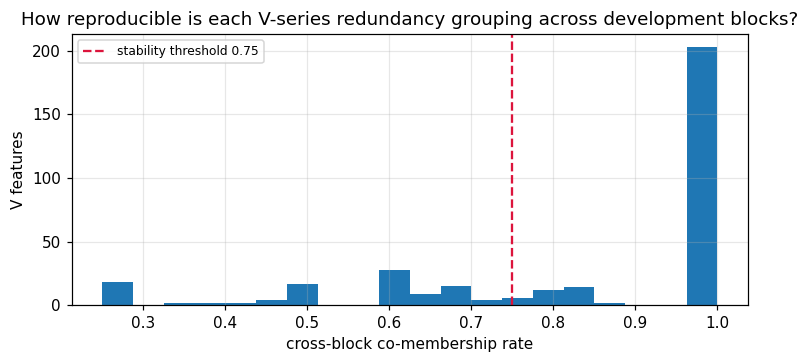

In [10]:
"""Section 7 - V-series redundancy, cross-block stability and representatives."""


def evenly_spaced_sample(frame: pd.DataFrame, max_rows: int) -> pd.DataFrame:
    """Return at most ``max_rows`` deterministic, evenly spaced rows."""
    if max_rows < 1:
        raise ValueError(f"max_rows must be positive, got {max_rows}.")
    if len(frame) <= max_rows:
        return frame
    positions = np.linspace(0, len(frame) - 1, num=max_rows, dtype=np.int64)
    return frame.iloc[positions]


def cluster_v_features_by_block(frame: pd.DataFrame, features: Sequence[str],
                                block: int, block_column: str = "chrono_block",
                                distance_threshold: float = CONFIG["CLUSTER_DISTANCE_THRESHOLD"],
                                sample_rows: int = CONFIG["CORR_SAMPLE_ROWS"],
                                seed: int = RANDOM_SEED) -> Dict[str, Any]:
    """Cluster features within ONE block using distance = 1 - |Spearman|.

    An evenly-spaced (not random) sample is drawn when the block exceeds
    ``sample_rows``, which preserves the chronology inside the block instead of
    over-weighting any part of it, and is deterministic. Average linkage on the
    condensed distance matrix keeps memory at O(k^2) for k features and avoids
    any dense row-by-row adjacency structure.

    Returns:
        dict with cluster_map (feature -> cluster id), n_features, n_rows_used,
        block, and the approximation note describing any sampling applied.
    """
    block_frame = frame.loc[frame[block_column] == block, list(features)]
    n_rows = len(block_frame)
    note = "full block"
    if n_rows > sample_rows:
        block_frame = evenly_spaced_sample(block_frame, sample_rows)
        note = (f"evenly spaced deterministic sample of the block "
                f"({len(block_frame):,} of {n_rows:,} rows); APPROXIMATION")
    usable = [c for c in features if block_frame[c].notna().sum() >= CONFIG["MIN_NON_MISSING"]
              and block_frame[c].nunique(dropna=True) > 1]
    if len(usable) < 2:
        return {"cluster_map": {}, "n_features": len(usable), "n_rows_used": len(block_frame),
                "block": int(block), "note": note + "; too few usable features to cluster"}
    corr = block_frame[usable].corr(method="spearman", min_periods=CONFIG["MIN_NON_MISSING"])
    distance = (1 - corr.abs()).to_numpy()
    distance = np.nan_to_num(distance, nan=1.0)
    np.fill_diagonal(distance, 0.0)
    distance = np.clip((distance + distance.T) / 2, 0, None)
    linkage_matrix = linkage(squareform(distance, checks=False), method="average")
    labels = fcluster(linkage_matrix, t=distance_threshold, criterion="distance")
    return {"cluster_map": {f: int(l) for f, l in zip(usable, labels)},
            "n_features": len(usable), "n_rows_used": int(len(block_frame)),
            "block": int(block), "note": note}


def assess_cluster_stability(cluster_maps: Mapping[int, Mapping[str, int]],
                             features: Sequence[str]) -> pd.DataFrame:
    """Measure how often two features co-cluster across development blocks.

    For every feature pair assessable in at least two blocks, the co-membership
    rate is the share of those blocks in which the pair shares a cluster. A
    feature's ``cluster_stability`` is the mean co-membership rate over the
    partners it shares its reference-block cluster with; a singleton scores 1.0
    only if it is a singleton everywhere, and NaN when it was never assessable.
    """
    blocks = sorted(cluster_maps)
    if len(blocks) < 2:
        raise ValueError("Cluster stability needs at least two blocks.")
    reference = cluster_maps[blocks[0]]
    rows = []
    for feature in features:
        if feature not in reference:
            rows.append({"feature": feature, "cluster_id": None,
                         "cluster_stability": np.nan, "n_blocks_assessed": 0,
                         "partners": ""})
            continue
        partners = [f for f, c in reference.items()
                    if c == reference[feature] and f != feature]
        assessed = [b for b in blocks if feature in cluster_maps[b]]
        if not partners:
            singleton_rate = float(np.mean([
                sum(1 for f, c in cluster_maps[b].items()
                    if c == cluster_maps[b][feature] and f != feature) == 0
                for b in assessed])) if assessed else np.nan
            rows.append({"feature": feature, "cluster_id": int(reference[feature]),
                         "cluster_stability": singleton_rate,
                         "n_blocks_assessed": len(assessed), "partners": ""})
            continue
        rates = []
        for partner in partners:
            shared = [b for b in assessed if partner in cluster_maps[b]]
            if shared:
                rates.append(np.mean([cluster_maps[b][feature] == cluster_maps[b][partner]
                                      for b in shared]))
        rows.append({"feature": feature, "cluster_id": int(reference[feature]),
                     "cluster_stability": float(np.mean(rates)) if rates else np.nan,
                     "n_blocks_assessed": len(assessed),
                     "partners": ", ".join(sorted(partners)[:8])
                                 + (" ..." if len(partners) > 8 else "")})
    return pd.DataFrame(rows)


def select_cluster_representatives(frame: pd.DataFrame, stability: pd.DataFrame,
                                   target: str = TARGET_COLUMN,
                                   stability_threshold: float = CONFIG["CLUSTER_STABILITY_THRESHOLD"],
                                   sample_rows: int = CONFIG["CORR_SAMPLE_ROWS"],
                                   seed: int = RANDOM_SEED) -> pd.DataFrame:
    """Pick one representative per sufficiently stable cluster.

    Ranking key, applied in this exact order so ties are broken deterministically
    and never by dict or file ordering:
        1. higher mutual information with the target (DEVELOPMENT rows only),
        2. lower development missing rate,
        3. lexicographically smaller feature name.

    ``frame`` must be development-only; the caller passes it through the leakage
    auditor first, and this function never receives an OOT target column.
    """
    if target not in frame.columns:
        raise KeyError(f"'{target}' is required to score representatives.")
    stable = stability[stability.cluster_id.notna()
                       & (stability.cluster_stability >= stability_threshold)]
    rows = []
    for cluster_id, members in stable.groupby("cluster_id"):
        columns = sorted(members.feature)
        subset = frame[columns + [target]]
        if len(subset) > sample_rows:
            subset = evenly_spaced_sample(subset, sample_rows)
        filled = subset[columns].astype(float)
        filled = filled.replace([np.inf, -np.inf], np.nan)
        # Median imputation for the MI estimate only; medians come from the same
        # development sample and are never applied to OOT or to the modelling data.
        filled = filled.fillna(filled.median(numeric_only=True)).fillna(0.0)
        try:
            mi = mutual_info_classif(filled.to_numpy(), subset[target].to_numpy(),
                                     discrete_features=False, random_state=seed)
        except ValueError as exc:
            LOG.warning("Mutual information failed for cluster %s (%s). Falling back "
                        "to the completeness + name ordering and recording the "
                        "fallback in the reason.", cluster_id, exc)
            mi = np.full(len(columns), np.nan)
        missing_rate = frame[columns].isna().mean()
        ranked = sorted(
            range(len(columns)),
            key=lambda i: (-(mi[i] if np.isfinite(mi[i]) else -1.0),
                           float(missing_rate[columns[i]]), columns[i]),
        )
        best = ranked[0]
        for i, column in enumerate(columns):
            rows.append({
                "cluster_id": int(cluster_id), "feature": column,
                "cluster_size": len(columns),
                "mutual_information_dev": float(mi[i]) if np.isfinite(mi[i]) else None,
                "development_missing_rate": float(missing_rate[column]),
                "is_representative": i == best,
                "selection_reason": (
                    "highest development mutual information; ties broken by lower "
                    "missing rate then lexicographic name"
                    if i == best else
                    f"redundant with {columns[best]} (same stable cluster)"),
            })
    return pd.DataFrame(rows)


if V_SERIES:
    _v_missing_dev = dev_df[V_SERIES].isna().mean()
    V_USABLE = sorted([c for c in V_SERIES
                       if _v_missing_dev[c] * 100 < CONFIG["V_MAX_MISSING_PCT"]],
                      key=lambda c: int(c[1:]))
    V_TOO_SPARSE = [c for c in V_SERIES if c not in V_USABLE]
    print(f"Workload estimate: {len(V_USABLE)} V columns x {len(DEV_BLOCKS)} development "
          f"blocks; each block correlates a {len(V_USABLE)}x{len(V_USABLE)} Spearman "
          f"matrix on at most {CONFIG['CORR_SAMPLE_ROWS']:,} rows "
          f"(~{len(V_USABLE) ** 2 * 8 / 1e6:.0f} MB per matrix, one at a time).")

    CLUSTER_MAPS: Dict[int, Dict[str, int]] = {}
    CLUSTER_NOTES: Dict[int, str] = {}
    for block in DEV_BLOCKS:
        AUDITOR.guard(f"v_cluster_block{block}", df.loc[df.chrono_block == block, [ID_COLUMN]])
        result = cluster_v_features_by_block(dev_df, V_USABLE, block=block)
        CLUSTER_MAPS[block] = result["cluster_map"]
        CLUSTER_NOTES[block] = result["note"]
        AUDITOR.register_fit(f"v_clustering_block{block}", "clustering",
                             df.loc[df.chrono_block == block, ID_COLUMN].to_numpy(), [block])
        LOG.info("Block %d: %d features clustered into %d clusters (%s).", block,
                 result["n_features"], len(set(result["cluster_map"].values())), result["note"])

    CLUSTER_STABILITY = assess_cluster_stability(CLUSTER_MAPS, V_USABLE)
    AUDITOR.guard("v_representative_selection", dev_df[[ID_COLUMN]])
    V_REPRESENTATIVES = select_cluster_representatives(dev_df, CLUSTER_STABILITY)
    AUDITOR.register_fit("v_representative_selection", "feature_selection",
                         dev_df[ID_COLUMN].to_numpy(), DEV_BLOCKS)

    V_SUMMARY = (CLUSTER_STABILITY
                 .merge(V_REPRESENTATIVES[["feature", "cluster_size",
                                           "mutual_information_dev", "is_representative",
                                           "selection_reason"]],
                        on="feature", how="left")
                 .merge(feature_risk[["feature", "PSI_max_development_only", "verdict"]]
                        .rename(columns={"verdict": "temporal_verdict"}),
                        on="feature", how="left"))
    V_SUMMARY["development_missing_rate"] = V_SUMMARY["feature"].map(_v_missing_dev)
    V_SUMMARY["stable_cluster"] = V_SUMMARY["cluster_stability"] >= CONFIG["CLUSTER_STABILITY_THRESHOLD"]
    V_SUMMARY["final_action"] = np.where(
        ~V_SUMMARY["stable_cluster"].fillna(False), "monitor",
        np.where(V_SUMMARY["is_representative"].fillna(False), "keep", "tag_not_drop"))

    _multi = V_SUMMARY[V_SUMMARY.cluster_size.fillna(1) > 1]
    print(f"\nUsable V columns: {len(V_USABLE)} (excluded as too sparse: {len(V_TOO_SPARSE)}).")
    print(f"Clusters judged stable across all {len(DEV_BLOCKS)} development blocks "
          f"(co-membership >= {CONFIG['CLUSTER_STABILITY_THRESHOLD']}): "
          f"{int(V_SUMMARY.loc[V_SUMMARY.stable_cluster.fillna(False), 'cluster_id'].nunique())}.")
    print(f"Columns inside a stable multi-member cluster: {len(_multi)}; "
          f"representatives kept: {int(V_SUMMARY.is_representative.fillna(False).sum())}.")
    print("\nLargest stable clusters:")
    print(_multi.sort_values(["cluster_size", "cluster_id", "feature"], ascending=[False, True, True])
          .head(15)[["cluster_id", "feature", "cluster_size", "cluster_stability",
                     "mutual_information_dev", "development_missing_rate",
                     "is_representative", "final_action"]].to_string(index=False))
    print("\nNo dimensionality reduction is FITTED here. Redundancy is a diagnosis; "
          "any reducer must be refitted inside each training fold to stay leakage-safe.")

    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.hist(CLUSTER_STABILITY.cluster_stability.dropna(), bins=20)
    ax.axvline(CONFIG["CLUSTER_STABILITY_THRESHOLD"], color="crimson", ls="--",
               label=f"stability threshold {CONFIG['CLUSTER_STABILITY_THRESHOLD']}")
    ax.set_xlabel("cross-block co-membership rate")
    ax.set_ylabel("V features")
    ax.set_title("How reproducible is each V-series redundancy grouping across "
                 "development blocks?")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    V_USABLE, V_TOO_SPARSE, CLUSTER_MAPS = [], [], {}
    CLUSTER_STABILITY = pd.DataFrame(columns=["feature", "cluster_id", "cluster_stability"])
    V_REPRESENTATIVES = pd.DataFrame(columns=["feature", "is_representative"])
    V_SUMMARY = pd.DataFrame(columns=["feature", "cluster_id", "final_action"])
    LOG.warning("No V-series columns: Section 7 is recorded as NOT COMPUTED.")

### Interpreting Section 7

The source notebook grouped V columns **once**, on a pooled development sample,
with Pearson correlation and union-find. Two problems: transitive union-find
chains features that are not mutually correlated, and a single pooled estimate
cannot distinguish a structural redundancy from one that happens to hold in a
particular stretch of time.

Measuring co-membership across blocks answers a sharper question: *would this
grouping still exist if I had looked at a different period?* Only groups that
survive that test earn a representative. Everything else is returned to
`monitor`, which is an admission of uncertainty rather than a decision.

## 8. Entity and Graph Readiness Analysis

For each available candidate entity column — `card1`–`card6`, `addr1`, `addr2`,
`P_emaildomain`, `R_emaildomain`, `DeviceInfo`, `DeviceType` — the notebook
computes coverage, cardinality, singleton rate, frequency distribution,
persistence across blocks, the share of OOT values previously seen in
development, cold-start rate, warm/cold transaction counts, fraud prevalence for
each, the entity-degree distribution and fraud concentration by degree band.

**Cold-start rate is defined twice, and the two are never conflated:**

* *primary* — OOT rows whose non-missing entity value was unseen in development,
  divided by **OOT rows with a non-missing value for that field**;
* *secondary* — the same numerator divided by **all OOT rows**, which is smaller
  whenever the field is sparse.

**Two things this section deliberately does not do.** It does not compose
`card1 + addr1 + (day − D)` (or any other combination) into a synthetic customer
identity — that linkage rule is undocumented for these anonymised columns and
unvalidated here. And it does not treat a shared identifier as evidence that two
transactions belong to the same person; a shared value is a shared *attribute*.

09:25:19 | INFO    | Wrote ./artifacts/entity_cold_start_summary.csv


       entity  coverage  cardinality  singleton_rate  persistence_mean_blocks  share_in_all_blocks  oot_rows_non_missing  cold_start_rows  cold_start_rate  cold_start_rate_all_oot_rows
   DeviceInfo    0.2107         1639          0.2550                   2.1818               0.2282                 19130              374           0.0196                        0.0032
   DeviceType    0.2490            2          0.0000                   4.0000               1.0000                 23172                0           0.0000                        0.0000
P_emaildomain    0.8442           59          0.0000                   4.0000               1.0000                 97238                0           0.0000                        0.0000
R_emaildomain    0.2405           60          0.0000                   3.8500               0.8833                 23671                0           0.0000                        0.0000
        addr1    0.8862          328          0.3780                   1.86

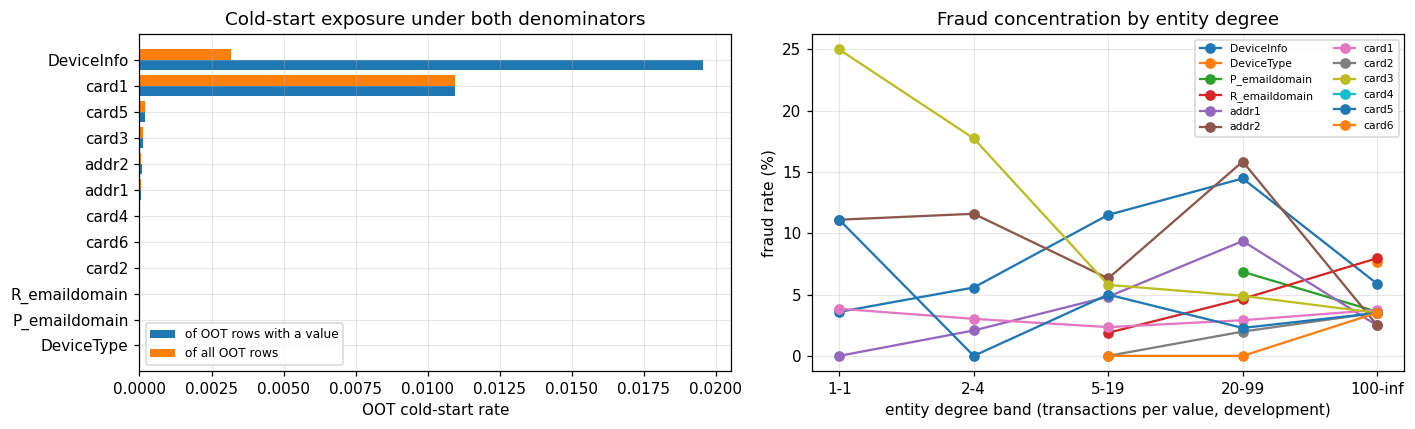

In [11]:
"""Section 8 - entity and graph readiness, cold start, degree concentration."""


def calculate_entity_persistence(frame: pd.DataFrame, column: str,
                                 block_column: str = "chrono_block") -> Dict[str, Any]:
    """Coverage, cardinality, singleton rate and cross-block persistence.

    ``persistence_mean_blocks`` is the average number of distinct blocks in
    which a value appears; ``share_in_all_blocks`` is the share of distinct
    values seen in every block. Both denominators are distinct non-missing
    values, not rows.
    """
    if column not in frame.columns:
        raise KeyError(f"Entity column '{column}' is absent.")
    values = frame[column]
    non_missing = values.notna()
    n_rows = int(len(frame))
    n_non_missing = int(non_missing.sum())
    if n_non_missing == 0:
        return {"entity": column, "assessable": False,
                "reason": "no non-missing values", "n_rows": n_rows,
                "non_missing_rows": 0, "coverage": 0.0, "cardinality": 0,
                "singleton_rate": np.nan, "persistence_mean_blocks": np.nan,
                "share_in_all_blocks": np.nan, "top1_share": np.nan}
    counts = values[non_missing].value_counts()
    per_value_blocks = (frame.loc[non_missing, [column, block_column]]
                        .groupby(column, observed=True)[block_column].nunique())
    n_blocks = int(frame[block_column].nunique())
    return {
        "entity": column, "assessable": True, "reason": "",
        "n_rows": n_rows,
        "non_missing_rows": n_non_missing,
        "coverage": n_non_missing / n_rows,
        "cardinality": int(counts.size),
        "singleton_rate": float((counts == 1).mean()),
        "top1_share": float(counts.iloc[0] / n_non_missing),
        "median_frequency": float(counts.median()),
        "p95_frequency": float(counts.quantile(0.95)),
        "persistence_mean_blocks": float(per_value_blocks.mean()),
        "share_in_all_blocks": float((per_value_blocks == n_blocks).mean()),
    }


def calculate_cold_start_rate(
    dev: pd.DataFrame, oot: pd.DataFrame, column: str
) -> Dict[str, Any]:
    """Measure OOT cold-start exposure without reading OOT labels.

    Primary rate: unseen, non-missing OOT rows divided by OOT rows
    with a non-missing value for this column.

    Secondary rate: the same numerator divided by all OOT rows.
    The set of previously seen values comes from development only.
    """
    for frame, label in ((dev, "dev"), (oot, "oot")):
        if column not in frame.columns:
            raise KeyError(
                f"Entity column '{column}' absent from the {label} frame."
            )

    seen = set(pd.unique(dev.loc[dev[column].notna(), column]))
    oot_values = oot[column]
    non_missing = oot_values.notna()
    n_oot_rows = int(len(oot))
    n_non_missing = int(non_missing.sum())

    if n_non_missing == 0:
        return {
            "entity": column,
            "assessable": False,
            "reason": "no non-missing OOT values",
            "n_dev_values_seen": len(seen),
            "oot_rows": n_oot_rows,
            "oot_rows_non_missing": 0,
            "cold_start_rows": 0,
            "warm_start_rows": 0,
            "cold_start_rate": np.nan,
            "cold_start_rate_all_oot_rows": np.nan,
            "unseen_value_share": np.nan,
            "cold_start_reliable": False,
        }

    is_cold = non_missing & ~oot_values.isin(seen)
    is_warm = non_missing & oot_values.isin(seen)
    n_cold = int(is_cold.sum())
    n_warm = int(is_warm.sum())

    return {
        "entity": column,
        "assessable": True,
        "reason": "",
        "n_dev_values_seen": len(seen),
        "oot_rows": n_oot_rows,
        "oot_rows_non_missing": n_non_missing,
        "cold_start_rows": n_cold,
        "warm_start_rows": n_warm,
        "cold_start_rate": n_cold / n_non_missing,
        "cold_start_rate_all_oot_rows": n_cold / n_oot_rows,
        "unseen_value_share": float(
            (~pd.Index(pd.unique(oot_values[non_missing]))
              .isin(list(seen))).mean()
        ),
        "cold_start_reliable": n_cold >= CONFIG["MIN_GROUP_N"],
    }


def summarize_degree_fraud_concentration(frame: pd.DataFrame, column: str,
                                         target: str = TARGET_COLUMN,
                                         bands: Sequence[int] = (1, 2, 5, 20, 100)) -> pd.DataFrame:
    """Fraud concentration by entity degree band, computed from an aggregated table.

    "Degree" here is the transaction count attached to an entity value within
    the supplied frame - a bipartite transaction-to-entity degree. No dense
    adjacency matrix is materialised: the whole computation is a value_counts
    join, which is why it scales to 590k rows.
    """
    if column not in frame.columns:
        raise KeyError(f"Entity column '{column}' is absent.")
    non_missing = frame[column].notna()
    if not non_missing.any():
        return pd.DataFrame(columns=["entity", "degree_band", "n_rows", "positives",
                                     "fraud_rate", "share_of_rows", "share_of_positives"])
    degree = frame.loc[non_missing, column].map(frame.loc[non_missing, column].value_counts())
    edges = list(bands) + [np.inf]
    labels = [f"{edges[i]}-{edges[i + 1] - 1 if np.isfinite(edges[i + 1]) else 'inf'}"
              for i in range(len(edges) - 1)]
    band = pd.cut(degree, bins=[b - 0.5 for b in edges[:-1]] + [np.inf],
                  labels=labels, right=True)
    y = frame.loc[non_missing, target]
    grouped = pd.DataFrame({"band": band, "y": y}).groupby("band", observed=False)["y"]
    out = grouped.agg(n_rows="size", positives="sum").reset_index()
    out["fraud_rate"] = out["positives"] / out["n_rows"].replace(0, np.nan)
    out["share_of_rows"] = out["n_rows"] / out["n_rows"].sum()
    out["share_of_positives"] = out["positives"] / max(int(out["positives"].sum()), 1)
    out.insert(0, "entity", column)
    out = out.rename(columns={"band": "degree_band"})
    return out


if ENTITY_COLUMNS:
    AUDITOR.guard("entity_seen_value_sets", dev_df[[ID_COLUMN]])
    _persistence = [calculate_entity_persistence(dev_df, c) for c in ENTITY_COLUMNS]
    _cold = [calculate_cold_start_rate(dev_df, oot_df, c) for c in ENTITY_COLUMNS]
    for column in ENTITY_COLUMNS:
        AUDITOR.register_fit(f"seen_values::{column}", "category_map",
                             dev_df[ID_COLUMN].to_numpy(), DEV_BLOCKS)

    ENTITY_SUMMARY = (pd.DataFrame(_persistence)
                      .merge(pd.DataFrame(_cold), on="entity", how="outer",
                             suffixes=("_dev", "_oot")))
    ENTITY_COLD_START_PATH = os.path.join(OUTPUT_DIRECTORY, "entity_cold_start_summary.csv")
    ENTITY_SUMMARY.to_csv(ENTITY_COLD_START_PATH, index=False)
    LOG.info("Wrote %s", ENTITY_COLD_START_PATH)

    DEGREE_CONCENTRATION = pd.concat(
        [summarize_degree_fraud_concentration(dev_df, c) for c in ENTITY_COLUMNS],
        ignore_index=True)

    print(ENTITY_SUMMARY[["entity", "coverage", "cardinality", "singleton_rate",
                          "persistence_mean_blocks", "share_in_all_blocks",
                          "oot_rows_non_missing", "cold_start_rows",
                          "cold_start_rate", "cold_start_rate_all_oot_rows"
                          ]]
          .round(4).to_string(index=False))
    print("\nDenominators: coverage and cold_start_rate_all_oot_rows use ALL rows of "
          "their frame; cold_start_rate uses only OOT rows with a non-missing value; "
          "singleton_rate and persistence use distinct values, not rows.")
    print("\nInterpretation limits: card/address/email/device columns are anonymised. "
          "A shared value is a shared ATTRIBUTE, not proof of a shared person. No "
          "composite customer identity is constructed here, because no documented "
          "linkage rule has been validated for these columns.")
    print("\nFraud concentration by entity degree band (development rows):")
    print(DEGREE_CONCENTRATION.round(5).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    _cs = ENTITY_SUMMARY.dropna(subset=["cold_start_rate"]).sort_values("cold_start_rate")
    _idx = np.arange(len(_cs))
    axes[0].barh(_idx - 0.2, _cs.cold_start_rate, height=0.4,
                 label="of OOT rows with a value")
    axes[0].barh(_idx + 0.2, _cs.cold_start_rate_all_oot_rows, height=0.4,
                 label="of all OOT rows")
    axes[0].set_yticks(_idx)
    axes[0].set_yticklabels(_cs.entity)
    axes[0].set_xlabel("OOT cold-start rate")
    axes[0].set_title("Cold-start exposure under both denominators")
    axes[0].legend(fontsize=8)
    for entity, part in DEGREE_CONCENTRATION.groupby("entity"):
        axes[1].plot(part.degree_band.astype(str), 100 * part.fraud_rate,
                     marker="o", label=entity)
    axes[1].set_xlabel("entity degree band (transactions per value, development)")
    axes[1].set_ylabel("fraud rate (%)")
    axes[1].set_title("Fraud concentration by entity degree")
    axes[1].legend(fontsize=7, ncol=2)
    plt.tight_layout()
    plt.show()
else:
    ENTITY_SUMMARY = pd.DataFrame()
    DEGREE_CONCENTRATION = pd.DataFrame()
    ENTITY_COLD_START_PATH = None
    LOG.warning("No candidate entity columns present: Section 8 is NOT COMPUTED.")

### Interpreting Section 8

Cold-start exposure is the single most consequential number for a graph-tabular
model. Any encoding built from an entity's history — frequency, running mean,
node embedding, degree — is **undefined** for a value first seen in the holdout,
and the share of the holdout in that position bounds how much of the graph story
can transfer at all. High singleton rates carry the same warning at the value
level: an entity seen once contributes a degree-1 node with no neighbourhood to
aggregate over.

Degree bands are computed from an aggregated `value_counts` table. No dense
adjacency matrix is materialised anywhere, which is what keeps this affordable at
590k rows and is the pattern any later graph pre-analysis should follow.

## 9. Block-Count Sensitivity Analysis

The 5-block split is a choice. If the conclusions depend on it, they are
artefacts. The key drift diagnostics are recomputed at 4, 5, 6 and 8 blocks;
each configuration reserves its own final chronological block as OOT and
**re-learns every reference statistic from its own development rows**. Nothing —
bin edges, cut points, fitted objects — is reused across configurations, because
an object learned under one split is not a development-only object under another.

Workload estimate: 4 configurations x 282 features, each re-splitting 590,540 rows.


09:27:48 | INFO    | Sensitivity configuration with 4 blocks complete (development blocks 1-3, OOT block 4).
09:30:25 | INFO    | Sensitivity configuration with 5 blocks complete (development blocks 1-4, OOT block 5).
09:33:09 | INFO    | Sensitivity configuration with 6 blocks complete (development blocks 1-5, OOT block 6).
09:36:04 | INFO    | Sensitivity configuration with 8 blocks complete (development blocks 1-7, OOT block 8).
09:36:04 | INFO    | Wrote ./artifacts/block_sensitivity_summary.csv



Features whose verdict is identical under 4, 5, 6 and 8 blocks: 156 of 282.
Features whose verdict changes with the block count: ['C10', 'C4', 'C8', 'C9', 'D13', 'D14', 'D3', 'D6', 'D9', 'TransactionAmt', 'V167', 'V168', 'V169', 'V170', 'V171', 'V172', 'V173', 'V174', 'V175', 'V176', 'V177', 'V178', 'V179', 'V180', 'V181', 'V182', 'V183', 'V184', 'V185', 'V186', 'V187', 'V188', 'V189', 'V190', 'V191', 'V192', 'V193', 'V194', 'V195', 'V196', 'V197', 'V198', 'V199', 'V200', 'V201', 'V202', 'V203', 'V204', 'V205', 'V206', 'V207', 'V208', 'V209', 'V210', 'V211', 'V212', 'V213', 'V214', 'V215', 'V216', 'V217', 'V218', 'V219', 'V220', 'V221', 'V222', 'V223', 'V224', 'V225', 'V226', 'V227', 'V228', 'V229', 'V230', 'V231', 'V232', 'V233', 'V234', 'V235', 'V236', 'V237', 'V238', 'V239', 'V240', 'V241', 'V242', 'V243', 'V244', 'V245', 'V246', 'V247', 'V248', 'V249', 'V250', 'V251', 'V252', 'V253', 'V254', 'V255', 'V256', 'V257', 'V258', 'V259', 'V260', 'V261', 'V262', 'V263', 'V264', 'V265', 'V

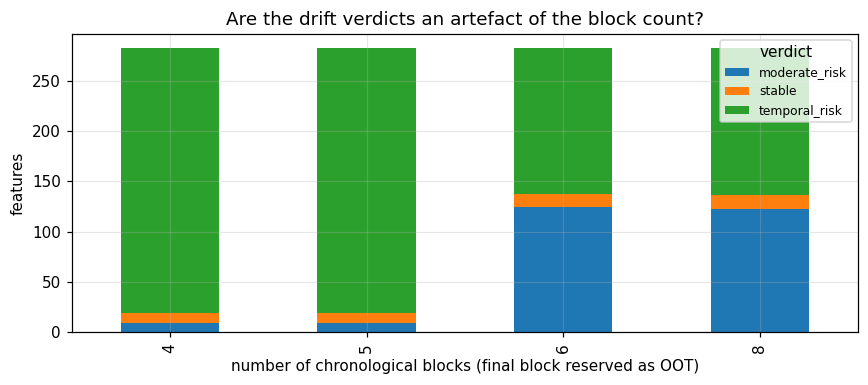

In [12]:
"""Section 9 - block-count sensitivity of the drift conclusions."""


def run_block_sensitivity(frame: pd.DataFrame, features: Sequence[str],
                          block_counts: Sequence[int] = CONFIG["SENSITIVITY_BLOCK_COUNTS"],
                          time_column: str = TIME_COLUMN,
                          id_column: str = ID_COLUMN) -> pd.DataFrame:
    """Recompute the key drift flags under several block-count configurations.

    For each configuration the split is rebuilt from scratch, the final
    chronological block becomes that configuration's OOT, and every reference
    statistic - bin edges, decile cut point, verdict rule input - is re-learned
    from that configuration's development rows only. Nothing is reused across
    configurations, because a bin edge learned under a 5-block split is not a
    development-only object under an 8-block split.

    Returns:
        Long DataFrame: one row per (n_blocks, feature) with psi_max_dev,
        spearman_corr_time, lift_stability and the resulting verdict.
    """
    rows = []
    for n_blocks in block_counts:
        labels = create_temporal_blocks(frame, n_blocks, time_column, id_column)
        local = frame[[id_column, time_column, "elapsed_days"] + list(features)].copy()
        local["chrono_block"] = labels
        local[TARGET_COLUMN] = frame[TARGET_COLUMN]
        dev_blocks = list(range(1, n_blocks))
        local_dev = local[local["chrono_block"] < n_blocks]
        local_auditor = LeakageAuditor(
            oot_ids=local.loc[local["chrono_block"] == n_blocks, id_column].to_numpy(),
            oot_blocks=[n_blocks])
        local_auditor.guard(f"sensitivity_{n_blocks}_blocks", local_dev[[id_column]])

        spearman = calculate_spearman_time_risk(local_dev, features).set_index("feature")
        for feature in features:
            reference = local_dev.loc[local_dev["chrono_block"] == dev_blocks[0], feature]
            edges = learn_psi_bins(reference)
            psis = []
            for block in dev_blocks[1:]:
                psis.append(calculate_psi(
                    reference, local_dev.loc[local_dev["chrono_block"] == block, feature],
                    edges=edges)["psi"])
            psis = [p for p in psis if np.isfinite(p)]
            psi_max = max(psis) if psis else np.nan

            values = local_dev[feature]
            values = values[pd.to_numeric(values, errors="coerce").map(np.isfinite)]
            cut = (float(np.quantile(values, CONFIG["TOP_DECILE_QUANTILE"]))
                   if len(values) >= CONFIG["MIN_NON_MISSING"] else float("nan"))
            lifts = {}
            for block in dev_blocks:
                result = calculate_top_decile_lift(
                    local.loc[local["chrono_block"] == block, [feature, TARGET_COLUMN]],
                    feature, cut)
                if result["assessable"]:
                    lifts[block] = result["lift"]
            stability = calculate_lift_stability(lifts)

            corr = spearman.loc[feature, "spearman_corr_time"] if feature in spearman.index else np.nan
            band = classify_psi(psi_max)
            strong_time = np.isfinite(corr) and abs(corr) >= CONFIG["SPEARMAN_RISK_THRESHOLD"]
            unstable = (stability["lift_stability"] is not None
                        and stability["lift_stability"] < CONFIG["LIFT_STABILITY_THRESHOLD"])
            if not np.isfinite(psi_max) and not np.isfinite(corr):
                verdict = "insufficient_evidence"
            elif band == "severe_drift" or (strong_time and unstable):
                verdict = "temporal_risk"
            elif band == "moderate_drift" or strong_time or unstable:
                verdict = "moderate_risk"
            else:
                verdict = "stable"

            rows.append({"n_blocks": n_blocks, "oot_block": n_blocks, "feature": feature,
                         "psi_max_dev": psi_max, "psi_band": band,
                         "spearman_corr_time": corr,
                         "lift_stability": stability["lift_stability"],
                         "n_lift_blocks": stability["n_blocks"], "verdict": verdict})
        LOG.info("Sensitivity configuration with %d blocks complete "
                 "(development blocks 1-%d, OOT block %d).", n_blocks, n_blocks - 1, n_blocks)
    return pd.DataFrame(rows)


# Restrict the sensitivity sweep to the families whose verdicts drive the
# protocol (D-series plus the amount) and any feature currently flagged, which
# keeps the four re-splits affordable without cherry-picking stable features.
SENSITIVITY_FEATURES = sorted(set(
    [c for c in AUDIT_FEATURES if family_of(c) in {"D", "amount", "distance"}]
    + feature_risk.loc[feature_risk.verdict.isin(["temporal_risk", "moderate_risk"]),
                       "feature"].tolist()
))
print(f"Workload estimate: {len(CONFIG['SENSITIVITY_BLOCK_COUNTS'])} configurations x "
      f"{len(SENSITIVITY_FEATURES)} features, each re-splitting {len(df):,} rows.")

SENSITIVITY_SOURCE = dev_df.copy()
_original_oot_ids = set(oot_df[ID_COLUMN].tolist())
if not _original_oot_ids.isdisjoint(set(SENSITIVITY_SOURCE[ID_COLUMN].tolist())):
    raise AssertionError("Sensitivity source contains original OOT TransactionIDs.")
BLOCK_SENSITIVITY = run_block_sensitivity(SENSITIVITY_SOURCE, SENSITIVITY_FEATURES)

_baseline = BLOCK_SENSITIVITY[BLOCK_SENSITIVITY.n_blocks == N_BLOCKS][["feature", "verdict"]] \
    .rename(columns={"verdict": "verdict_baseline"})
BLOCK_SENSITIVITY = BLOCK_SENSITIVITY.merge(_baseline, on="feature", how="left")
BLOCK_SENSITIVITY["verdict_changed_vs_baseline"] = (
    BLOCK_SENSITIVITY["verdict"] != BLOCK_SENSITIVITY["verdict_baseline"])

_agreement = (BLOCK_SENSITIVITY.groupby("feature")["verdict"].nunique()
              .rename("distinct_verdicts").reset_index())
_agreement["robust_to_block_count"] = _agreement["distinct_verdicts"] == 1
BLOCK_SENSITIVITY = BLOCK_SENSITIVITY.merge(_agreement, on="feature", how="left")

BLOCK_SENSITIVITY_PATH = os.path.join(OUTPUT_DIRECTORY, "block_sensitivity_summary.csv")
BLOCK_SENSITIVITY.to_csv(BLOCK_SENSITIVITY_PATH, index=False)
LOG.info("Wrote %s", BLOCK_SENSITIVITY_PATH)

_unstable = _agreement[~_agreement.robust_to_block_count]["feature"].tolist()
print(f"\nFeatures whose verdict is identical under 4, 5, 6 and 8 blocks: "
      f"{int(_agreement.robust_to_block_count.sum())} of {len(_agreement)}.")
print(f"Features whose verdict changes with the block count: "
      f"{_unstable if _unstable else 'none'}")
print("\nVerdict counts by configuration:")
print(BLOCK_SENSITIVITY.pivot_table(index="verdict", columns="n_blocks",
                                    values="feature", aggfunc="count", fill_value=0)
      .to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
_pivot = BLOCK_SENSITIVITY.pivot_table(index="n_blocks", columns="verdict",
                                       values="feature", aggfunc="count", fill_value=0)
_pivot.plot(kind="bar", stacked=True, ax=ax)
ax.set_xlabel("number of chronological blocks (final block reserved as OOT)")
ax.set_ylabel("features")
ax.set_title("Are the drift verdicts an artefact of the block count?")
ax.legend(fontsize=8, title="verdict")
plt.tight_layout()
plt.show()

### Interpreting Section 9

Read this table as a robustness statement about the *conclusions*, not about the
data. A feature whose verdict is identical under all four configurations is
robust to this particular arbitrary choice — which is weaker than "correct", but
considerably stronger than a single split. Features whose verdicts move are
demoted to `monitor` in the ledger and named explicitly, because a verdict that
depends on how many pieces the timeline was cut into should not be presented with
the same confidence as one that does not.

## 10. Threshold Justification

The source notebook flagged drift at `|Pearson r| >= 0.30` with no derivation.
That is replaced here by: Spearman (the association is monotone, not linear, and
the tails are heavy), the full empirical distribution of `|ρ|` across development
features, and a quantile-derived alternative cut-off computed from development
rows only. The configured value remains configurable and is fixed before any OOT
number is consulted.

{
  "n_features": 371,
  "quantile": 0.99,
  "derived_threshold": 0.2892023546721702,
  "median_abs_corr": 0.036274814554646956,
  "p90_abs_corr": 0.10838906393647053,
  "max_abs_corr": 0.3325707979066202,
  "configured_threshold": 0.3,
  "share_above_configured": 0.008086253369272238
}

Reading this table: the configured threshold (0.3) flags 0.8% of assessable development features. The empirically derived cut-off is the 99% quantile of the same distribution. Neither is a law: a threshold sets how much review capacity is spent, and it is deliberately fixed BEFORE any OOT number is consulted.

Statistical significance is not practical risk. At ~470k development rows a |Spearman| of 0.01 is significant at any conventional alpha and is practically irrelevant, which is why the verdict rule combines the correlation with PSI and with lift stability rather than relying on any single cut-off.


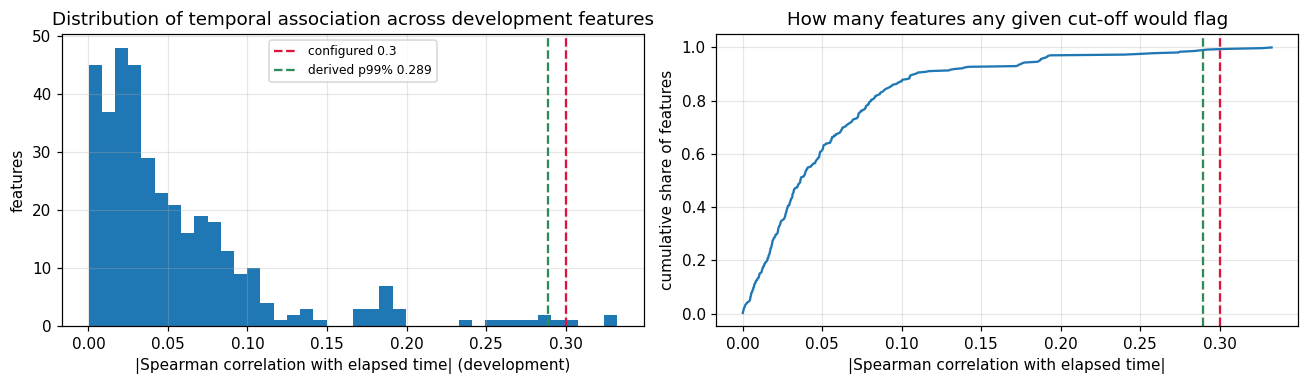

In [13]:
"""Section 10 - deriving the temporal-correlation threshold instead of asserting it."""


def derive_correlation_threshold(correlations: Sequence[float],
                                 quantile: float = 0.99) -> Dict[str, Any]:
    """Derive a temporal-correlation cut-off from the DEVELOPMENT distribution.

    The source notebook used ``DRIFT_CORR = 0.30`` on a Pearson correlation with
    no stated provenance. Two changes are made here:

      1. Spearman replaces Pearson, because the association of interest is
         monotone drift, not a linear relationship, and the D and V series have
         tails that dominate a Pearson estimate.
      2. The cut-off becomes an EMPIRICAL quantile of the observed |Spearman|
         distribution across development features, so it is a statement about
         this dataset ("the most time-associated 1% of features") rather than an
         imported constant. It is computed from development rows only.

    Returns the derived value alongside the configured one so the difference is
    visible and the choice remains the analyst's.
    """
    values = np.asarray([abs(c) for c in correlations if c is not None and np.isfinite(c)])
    if values.size == 0:
        raise ValueError("No finite correlations supplied; a threshold cannot be derived.")
    return {
        "n_features": int(values.size),
        "quantile": quantile,
        "derived_threshold": float(np.quantile(values, quantile)),
        "median_abs_corr": float(np.median(values)),
        "p90_abs_corr": float(np.quantile(values, 0.90)),
        "max_abs_corr": float(values.max()),
        "configured_threshold": CONFIG["SPEARMAN_RISK_THRESHOLD"],
        "share_above_configured": float((values >= CONFIG["SPEARMAN_RISK_THRESHOLD"]).mean()),
    }


AUDITOR.guard("correlation_threshold_derivation", dev_df[[ID_COLUMN]])
THRESHOLD_EVIDENCE = derive_correlation_threshold(
    feature_risk["spearman_corr_time"].tolist())
AUDITOR.register_fit("temporal_correlation_threshold", "threshold",
                     dev_df[ID_COLUMN].to_numpy(), DEV_BLOCKS)

print(json.dumps(THRESHOLD_EVIDENCE, indent=2))
print("\nReading this table: the configured threshold "
      f"({CONFIG['SPEARMAN_RISK_THRESHOLD']}) flags "
      f"{100 * THRESHOLD_EVIDENCE['share_above_configured']:.1f}% of assessable "
      "development features. The empirically derived cut-off is the "
      f"{THRESHOLD_EVIDENCE['quantile']:.0%} quantile of the same distribution. "
      "Neither is a law: a threshold sets how much review capacity is spent, and "
      "it is deliberately fixed BEFORE any OOT number is consulted.")
print("\nStatistical significance is not practical risk. At ~470k development rows "
      "a |Spearman| of 0.01 is significant at any conventional alpha and is "
      "practically irrelevant, which is why the verdict rule combines the "
      "correlation with PSI and with lift stability rather than relying on any "
      "single cut-off.")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
_abs_corr = feature_risk["spearman_corr_time"].abs().dropna()
axes[0].hist(_abs_corr, bins=40)
axes[0].axvline(CONFIG["SPEARMAN_RISK_THRESHOLD"], color="crimson", ls="--",
                label=f"configured {CONFIG['SPEARMAN_RISK_THRESHOLD']}")
axes[0].axvline(THRESHOLD_EVIDENCE["derived_threshold"], color="seagreen", ls="--",
                label=f"derived p{THRESHOLD_EVIDENCE['quantile']:.0%} "
                      f"{THRESHOLD_EVIDENCE['derived_threshold']:.3f}")
axes[0].set_xlabel("|Spearman correlation with elapsed time| (development)")
axes[0].set_ylabel("features")
axes[0].set_title("Distribution of temporal association across development features")
axes[0].legend(fontsize=8)

_sorted = np.sort(_abs_corr)
axes[1].plot(_sorted, np.arange(1, _sorted.size + 1) / _sorted.size)
axes[1].axvline(CONFIG["SPEARMAN_RISK_THRESHOLD"], color="crimson", ls="--")
axes[1].axvline(THRESHOLD_EVIDENCE["derived_threshold"], color="seagreen", ls="--")
axes[1].set_xlabel("|Spearman correlation with elapsed time|")
axes[1].set_ylabel("cumulative share of features")
axes[1].set_title("How many features any given cut-off would flag")
plt.tight_layout()
plt.show()

### Interpreting Section 10

A threshold is a **capacity decision**: it determines how many features get human
review, and the honest way to set it is against the observed distribution, not
against a number inherited from a blog post. Two guarantees hold regardless of
the value chosen: it is derived from development data only, and PSI and lift
stability are carried alongside it, so no feature is condemned or exonerated by a
single statistic.

## 11. Machine-Readable Decisions Ledger

One JSON entry per feature: family, the ten diagnostic values (with `null`
preserved wherever a metric was not applicable or not estimable), verdict,
reason, action, decision scope, the evidence sections that produced it, the
configuration snapshot, the data hash, the code version and a timestamp.

`update_decisions_ledger` enforces the contract instead of trusting it: the
verdict and action vocabularies are closed, a non-empty reason is mandatory, and
at least one evidence section must be cited. A decision cannot enter the ledger
without its evidence.

In [14]:
"""Section 11 - the machine-readable decisions ledger."""


def _nullable(value: Any) -> Optional[float]:
    """Convert numpy/NaN values to JSON-safe floats, preserving null as null."""
    if value is None:
        return None
    if isinstance(value, (np.floating, float)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.integer, int)):
        return int(value)
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    return value


def update_decisions_ledger(ledger: Dict[str, Dict[str, Any]], feature: str,
                            feature_family: str, diagnostics: Mapping[str, Any],
                            verdict: str, reason: str, action: str,
                            evidence_sections: Sequence[str],
                            config_snapshot: Mapping[str, Any],
                            data_hash: str, code_version: str,
                            decision_scope: str = "development_only") -> Dict[str, Dict[str, Any]]:
    """Insert or replace one feature's entry in the decisions ledger.

    Contract enforced here rather than trusted:
      * ``verdict`` and ``action`` must be drawn from the allowed vocabularies;
      * a metric that was not computed stays ``null`` - it is never coerced to 0;
      * a non-empty ``reason`` and at least one evidence section are required for
        every verdict, so no decision can be recorded without its evidence.
    """
    allowed_verdicts = {"stable", "moderate_risk", "temporal_risk", "redundant",
                        "insufficient_evidence"}
    allowed_actions = {"keep", "drop", "tag_not_drop", "monitor", "investigate"}
    allowed_scopes = {"development_only", "oot_evaluation_only", "development_plus_oot_evaluation"}
    if verdict not in allowed_verdicts:
        raise ValueError(f"verdict '{verdict}' is not one of {sorted(allowed_verdicts)}.")
    if action not in allowed_actions:
        raise ValueError(f"action '{action}' is not one of {sorted(allowed_actions)}.")
    if decision_scope not in allowed_scopes:
        raise ValueError(f"decision_scope {decision_scope!r} is not one of {sorted(allowed_scopes)}.")
    if not reason:
        raise ValueError(f"A reason is mandatory; '{feature}' supplied none.")
    if not evidence_sections:
        raise ValueError(f"'{feature}' must cite at least one evidence section.")

    ledger[feature] = {
        "feature_family": feature_family,
        "diagnostic_results": {
            "psi_max": _nullable(diagnostics.get("psi_max")),
            "ks_stat": _nullable(diagnostics.get("ks_stat")),
            "ks_adjusted_pvalue": _nullable(diagnostics.get("ks_adjusted_pvalue")),
            "spearman_corr_time": _nullable(diagnostics.get("spearman_corr_time")),
            "lift_stability": _nullable(diagnostics.get("lift_stability")),
            "missingness_drift": _nullable(diagnostics.get("missingness_drift")),
            "cluster_id": _nullable(diagnostics.get("cluster_id")),
            "cluster_stability": _nullable(diagnostics.get("cluster_stability")),
            "mutual_information_dev": _nullable(diagnostics.get("mutual_information_dev")),
            "oot_cold_start_rate": _nullable(diagnostics.get("oot_cold_start_rate")),
        },
        "verdict": verdict,
        "reason": reason,
        "action": action,
        "decision_scope": decision_scope,
        "evidence_sections": list(evidence_sections),
        "config_snapshot": dict(config_snapshot),
        "data_hash": data_hash,
        "code_version": code_version,
        "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    return ledger


CONFIG_SNAPSHOT = {k: CONFIG[k] for k in [
    "RANDOM_SEED", "N_BLOCKS", "OOT_BLOCK", "PSI_BINS", "PSI_EPSILON",
    "PSI_MODERATE_THRESHOLD", "PSI_SEVERE_THRESHOLD", "KS_ALPHA",
    "TEMPORAL_CORRELATION_METHOD", "SPEARMAN_RISK_THRESHOLD",
    "CLUSTER_DISTANCE_THRESHOLD", "CLUSTER_STABILITY_THRESHOLD",
    "TOP_DECILE_QUANTILE", "MIN_POSITIVES_FOR_LIFT", "LIFT_STABILITY_THRESHOLD",
    "ENTITY_COLD_START_MODERATE_THRESHOLD", "ENTITY_COLD_START_HIGH_THRESHOLD",
    "FIXED_FPR"]}

DECISIONS_LEDGER: Dict[str, Dict[str, Any]] = {}
_cluster_lookup = (V_SUMMARY.set_index("feature") if len(V_SUMMARY) else pd.DataFrame())
_cold_lookup = (ENTITY_SUMMARY.set_index("entity")["cold_start_rate"].to_dict()
                if len(ENTITY_SUMMARY) else {})

for _, row in feature_risk.iterrows():
    feature = row["feature"]
    verdict, action, reason = row["verdict"], row["action"], row["reason"]
    sections = ["5. D-Series Temporal Risk Analysis"]
    cluster_id = cluster_stability_value = mi_value = None

    if len(_cluster_lookup) and feature in _cluster_lookup.index:
        entry = _cluster_lookup.loc[feature]
        cluster_id = entry.get("cluster_id")
        cluster_stability_value = entry.get("cluster_stability")
        mi_value = entry.get("mutual_information_dev")
        sections.append("7. V-Series Redundancy and Stability")
        if entry.get("final_action") == "tag_not_drop" and verdict == "stable":
            verdict = "redundant"
            action = "tag_not_drop"
            reason = (f"co-clusters with {entry.get('partners', '')} at distance "
                      f"<= {CONFIG['CLUSTER_DISTANCE_THRESHOLD']} in "
                      f"{entry.get('n_blocks_assessed', 0)} development blocks "
                      f"(stability {entry.get('cluster_stability')}); "
                      f"{entry.get('selection_reason', '')}")

    sensitivity_rows = BLOCK_SENSITIVITY[BLOCK_SENSITIVITY.feature == feature]
    if len(sensitivity_rows):
        sections.append("9. Block-Count Sensitivity Analysis")
        if not bool(sensitivity_rows["robust_to_block_count"].iloc[0]):
            reason += ("; verdict is NOT robust to the block count "
                       f"({sorted(set(sensitivity_rows.verdict))} under "
                       f"{sorted(set(sensitivity_rows.n_blocks))} blocks)")
            if action == "keep":
                action = "monitor"

    DECISIONS_LEDGER = update_decisions_ledger(
        DECISIONS_LEDGER, feature=feature, feature_family=row["family"],
        diagnostics={
            "psi_max": row["PSI_max_development_only"],
            "ks_stat": row["ks_stat"],
            "ks_adjusted_pvalue": row["ks_adjusted_pvalue"],
            "spearman_corr_time": row["spearman_corr_time"],
            "lift_stability": row["lift_stability"],
            "missingness_drift": row["missingness_drift"],
            "cluster_id": cluster_id,
            "cluster_stability": cluster_stability_value,
            "mutual_information_dev": mi_value,
            "oot_cold_start_rate": None,
        },
        verdict=verdict, reason=reason, action=action,
        evidence_sections=sections, config_snapshot=CONFIG_SNAPSHOT,
        data_hash=DATA_HASH["sha256"], code_version=CONFIG["CODE_VERSION"])

for entity in ENTITY_COLUMNS:
    rate = _cold_lookup.get(entity)
    reliable = (bool(ENTITY_SUMMARY.set_index("entity").loc[entity, "cold_start_reliable"])
                if len(ENTITY_SUMMARY) and "cold_start_reliable" in ENTITY_SUMMARY.columns
                else False)
    diagnostic = {
        "oot_cold_start_rate": (float(rate) if rate is not None and np.isfinite(rate) else None),
        "cold_start_reliable": reliable,
        "decision_scope": "oot_evaluation_only",
        "development_action_changed": False,
    }
    # OOT cold-start is evaluation evidence only. It may enrich an existing
    # development decision, but it must never create or overwrite verdict/action.
    if entity in DECISIONS_LEDGER:
        DECISIONS_LEDGER[entity].setdefault("evaluation_diagnostics", {})
        DECISIONS_LEDGER[entity]["evaluation_diagnostics"]["oot_cold_start"] = diagnostic

LEDGER_PATH = os.path.join(OUTPUT_DIRECTORY, "decisions_ledger.json")
_serialised = json.dumps(DECISIONS_LEDGER, indent=2, allow_nan=False)
with open(LEDGER_PATH, "w", encoding="utf-8") as handle:
    handle.write(_serialised)
LOG.info("Wrote %s (%d features).", LEDGER_PATH, len(DECISIONS_LEDGER))

_ledger_frame = pd.DataFrame([
    {"feature": k, "family": v["feature_family"], "verdict": v["verdict"],
     "action": v["action"]} for k, v in DECISIONS_LEDGER.items()])
print(_ledger_frame.groupby(["verdict", "action"]).size().rename("features")
      .reset_index().to_string(index=False))
print("\nExample entry:")
print(json.dumps(DECISIONS_LEDGER[_ledger_frame.feature.iloc[0]], indent=2)[:1200])
print("\n'tag_not_drop' means the column is retained and carried into modelling with "
      "a risk tag attached; it is NOT an automatic exclusion. 'drop' is reserved for "
      "columns with no usable content at all.")

09:36:06 | INFO    | Wrote ./artifacts/decisions_ledger.json (371 features).


              verdict       action  features
insufficient_evidence  investigate         1
        moderate_risk      monitor        13
            redundant tag_not_drop        23
               stable         keep        68
               stable      monitor         3
        temporal_risk tag_not_drop       263

Example entry:
{
  "feature_family": "C",
  "diagnostic_results": {
    "psi_max": 0.05029087097817326,
    "ks_stat": 0.10927286889965115,
    "ks_adjusted_pvalue": 0.0,
    "spearman_corr_time": 0.06099916706675135,
    "lift_stability": 0.8759263602153,
    "missingness_drift": 0.0,
    "cluster_id": null,
    "cluster_stability": null,
    "mutual_information_dev": null,
    "oot_cold_start_rate": null
  },
  "verdict": "stable",
  "reason": "dev PSI_max 0.050 below 0.1, |Spearman| 0.061 below 0.300",
  "action": "keep",
  "decision_scope": "development_only",
  "evidence_sections": [
    "5. D-Series Temporal Risk Analysis"
  ],
  "config_snapshot": {
    "RANDOM_SEED": 

### Interpreting Section 11

`tag_not_drop` is the deliberate middle path and the reason the action vocabulary
is not binary. It means: keep the column, carry the risk tag into modelling, and
test its removal as an **ablation** rather than assuming the removal is an
improvement. Dropping a temporally unstable feature is itself a modelling
decision with a cost, and this notebook does not have the evidence to make it.

`insufficient_evidence` is recorded explicitly for the same reason. An unrunnable
diagnostic is a fact about the data — a constant column, a near-empty block, too
few positives — and hiding it behind a default value would misrepresent the
audit's coverage.

## 12. Consolidated Findings

Assembled from the computed artifacts, with observed evidence, configured
decision rules, methodological interpretation and forward-looking
recommendations kept in separate blocks so they cannot be read as one another.

In [15]:
"""Section 12 - consolidated findings, assembled from computed objects only."""


def build_findings(feature_risk: pd.DataFrame, checks: pd.DataFrame,
                   sensitivity: pd.DataFrame, entity_summary: pd.DataFrame,
                   v_summary: pd.DataFrame, missing_tests: pd.DataFrame,
                   confounding: pd.DataFrame) -> Dict[str, Any]:
    """Collect the headline counts. Every value is read back from a computed
    artifact; nothing here is typed in by hand."""
    verdicts = feature_risk["verdict"].value_counts().to_dict()
    findings: Dict[str, Any] = {
        "leakage_checks_passed": int(checks["passed"].sum()) if len(checks) else 0,
        "leakage_checks_failed": int((~checks["passed"]).sum()) if len(checks) else 0,
        "failed_check_names": checks.loc[~checks["passed"], "check"].tolist() if len(checks) else [],
        "features_assessed": int(len(feature_risk)),
        "verdict_counts": {k: int(v) for k, v in verdicts.items()},
        "severe_psi_features": feature_risk.loc[
            feature_risk.PSI_band_development_only == "severe_drift", "feature"].tolist(),
        "moderate_psi_features": feature_risk.loc[
            feature_risk.PSI_band_development_only == "moderate_drift", "feature"].tolist(),
        "unstable_missingness_patterns": (
            confounding.loc[confounding.flag == "sign_reverses_in_some_strata",
                            "pattern_lead"].tolist() if len(confounding) else []),
        "missingness_patterns_supported": (
            int(missing_tests.keep_indicator.sum()) if len(missing_tests) else 0),
        "missingness_patterns_tested": (
            int(missing_tests.tested.sum()) if len(missing_tests) else 0),
        "stable_v_clusters": (
            int(v_summary.loc[v_summary.get("stable_cluster", pd.Series(dtype=bool))
                              .fillna(False), "cluster_id"].nunique()) if len(v_summary) else 0),
        "v_representatives_kept": (
            int(v_summary.get("is_representative", pd.Series(dtype=bool)).fillna(False).sum())
            if len(v_summary) else 0),
        "entity_columns_assessed": (entity_summary["entity"].tolist()
                                    if len(entity_summary) else []),
        "max_oot_cold_start_rate": (
            float(entity_summary["cold_start_rate"].max()) if len(entity_summary) else None),
        "features_robust_to_block_count": (
            int(sensitivity.drop_duplicates("feature")["robust_to_block_count"].sum())
            if len(sensitivity) else 0),
        "features_sensitive_to_block_count": (
            sensitivity.loc[~sensitivity.robust_to_block_count, "feature"].unique().tolist()
            if len(sensitivity) else []),
    }
    return findings


FINDINGS = build_findings(feature_risk, CHECKS, BLOCK_SENSITIVITY, ENTITY_SUMMARY,
                          V_SUMMARY, MISSINGNESS_TESTS, CONFOUNDING)

print("=== OBSERVED EVIDENCE (computed in this run) ===")
print(json.dumps(
    {k: (v if not isinstance(v, list) or len(v) <= 12 else v[:12] + ["..."])
     for k, v in FINDINGS.items()}, indent=2))

print("""
=== CONFIGURED DECISION RULES (chosen, not discovered) ===
  PSI bands            stable < {psi_mod}, moderate <= {psi_sev}, severe above
  KS multiplicity      Benjamini-Hochberg at alpha = {alpha}
  Temporal association Spearman, flag at |rho| >= {rho} (Section 10 shows the
                       empirical distribution this cut-off sits in)
  Lift stability       1 - coefficient of variation, "stable" at >= 0.75, and only
                       estimated with >= {minblocks} blocks and >= {minpos} positives
  Cluster redundancy   distance 1 - |Spearman| <= {cdist}, co-membership >= {cstab}
                       across development blocks
  Entity cold start    moderate at >= 5%, high at >= 20% of OOT rows with a value
""".format(psi_mod=CONFIG["PSI_MODERATE_THRESHOLD"], psi_sev=CONFIG["PSI_SEVERE_THRESHOLD"],
           alpha=CONFIG["KS_ALPHA"], rho=CONFIG["SPEARMAN_RISK_THRESHOLD"],
           minblocks=CONFIG["LIFT_STABILITY_MIN_BLOCKS"], minpos=CONFIG["MIN_POSITIVES_FOR_LIFT"],
           cdist=CONFIG["CLUSTER_DISTANCE_THRESHOLD"], cstab=CONFIG["CLUSTER_STABILITY_THRESHOLD"]))

print("""=== METHODOLOGICAL INTERPRETATION ===
  * Every fitted object above - bin edges, decile cut points, cluster maps,
    mutual-information scores, the correlation threshold, the seen-value sets -
    is registered in the leakage auditor with the blocks it was fitted on. The
    registry, printed in the run manifest, is the auditable form of the claim
    that OOT was quarantined.
  * OOT appears as an evaluation-only comparison sample and as the population
    whose cold-start exposure is measured. Development feature verdicts do not
    read OOT statistics. Entity cold-start classifications are explicitly marked
    decision_scope=oot_evaluation_only and must not be represented as development-only.
  * Association is not causation, and predictive lift is not an effect. A
    missingness indicator that separates fraud may be recording a failed join
    rather than customer behaviour; the ProductCD stratification in Section 6
    is what distinguishes the two, not the aggregate contrast.
  * Shared card, address, email-domain or device values are shared ATTRIBUTES.
    They do not establish that two transactions belong to one person, and no
    composite identity is built here.

=== RECOMMENDATIONS FOR LATER MODELLING (not results) ===
  1. Forward-chaining folds with an embargo; random cross-validation must never
     be the primary estimate.
  2. Fit every encoder, scaler, imputer and reducer inside the training fold.
     The redundancy groups above say what COULD be reduced, not a fitted reducer.
  3. Report PR-AUC and recall at a fixed FPR per block, and separately for
     warm-start and cold-start entities; ROC-AUC alone is inadequate at ~3.5%
     prevalence.
  4. Treat 'tag_not_drop' features as carried-with-a-tag, and test their removal
     as an ablation rather than assuming it.""")

=== OBSERVED EVIDENCE (computed in this run) ===
{
  "leakage_checks_passed": 5,
  "leakage_checks_failed": 0,
  "failed_check_names": [],
  "features_assessed": 371,
  "verdict_counts": {
    "temporal_risk": 263,
    "stable": 94,
    "moderate_risk": 13,
    "insufficient_evidence": 1
  },
  "severe_psi_features": [
    "C10",
    "C8",
    "C9",
    "D10",
    "D11",
    "D15",
    "D4",
    "V1",
    "V10",
    "V11",
    "V12",
    "V13",
    "..."
  ],
  "moderate_psi_features": [
    "C13",
    "C4",
    "D1",
    "D2",
    "D3",
    "D5",
    "D8",
    "D9",
    "V282",
    "V283",
    "TransactionAmt"
  ],
  "unstable_missingness_patterns": [
    "D13",
    "D14",
    "D15",
    "D2",
    "D3",
    "D5",
    "D6",
    "D7",
    "DeviceInfo",
    "M5",
    "M6",
    "P_emaildomain",
    "..."
  ],
  "missingness_patterns_supported": 27,
  "missingness_patterns_tested": 65,
  "stable_v_clusters": 119,
  "v_representatives_kept": 119,
  "entity_columns_assessed": [
    "DeviceIn

/tmp/ipykernel_16/1750737903.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  int(v_summary.get("is_representative", pd.Series(dtype=bool)).fillna(False).sum())


## 13. Thesis Defence Notes

Each note pairs a likely examiner criticism with the evidence this notebook now
produces, the limitation that remains, and what it implies for graph-tabular
fraud modelling.

**13.1 "Your split leaks — you computed statistics before splitting."**
*Evidence now produced:* the split is derived before any statistic; every fitted
object registers its rows and blocks in `LeakageAuditor` and is exported in
`run_manifest.json`; `guard()` raises at the call site if a quarantined
identifier reaches a fit, selection, threshold or clustering call; the quarantine
assertions run as pass/fail invariants.
*Remaining limitation:* the guard proves that OOT rows did not enter a *tracked*
call. It cannot detect leakage through analyst knowledge — a threshold chosen
because an earlier run's OOT result was disappointing. Only the fixed-before-
results discipline and the versioned config snapshot address that.
*Implication:* a graph model must extend the same registry to edge construction,
degrees and community assignments, all of which leak topologically even when
labels are hidden.

**13.2 "Your drift threshold is arbitrary."**
*Evidence now produced:* Spearman replaces an unsourced Pearson rule; Section 10
shows the full distribution of `|ρ|` and derives a quantile-based alternative;
PSI and lift stability provide two independent views; every band is configurable
and snapshotted into each decision.
*Remaining limitation:* the band boundaries (0.10 / 0.25) remain conventions.
They are labelled as configured decision rules everywhere they appear, but they
are not derived from a loss function.
*Implication:* the defensible version of "this feature drifts" is a cost
statement — how much performance is lost by keeping it — which requires a model
and therefore belongs to the next stage.

**13.3 "A significant KS test does not mean the drift matters."**
*Evidence now produced:* KS reports statistic, both sample sizes, raw and
BH-adjusted p-values; the interpretation text states that at these sample sizes
significance is near-automatic; verdicts require PSI or lift evidence, never a
p-value alone.
*Remaining limitation:* no minimum practically-important KS statistic is
specified, because none can be justified without downstream cost information.
*Implication:* drift monitoring in production should trigger on effect size and
on realised performance, not on test significance.

**13.4 "Missingness looks predictive because of product mix."**
*Evidence now produced:* patterns collapsed before testing (one test per
underlying signal); ProductCD stratification with per-stratum sample and positive
counts; an explicit sign-reversal flag; a direction-consistency requirement
across development blocks; BH correction.
*Remaining limitation:* ProductCD is one stratifier. Device, issuer and channel
could confound in the same way and are not adjusted for; no multivariate
adjustment is attempted.
*Implication:* missingness indicators should enter a graph-tabular model as
node/edge *attributes* carrying their provenance, not as free-standing
predictors, so their product dependence stays visible.

**13.5 "Your V-series groups are an artefact of one sample."**
*Evidence now produced:* per-block clustering, cross-block co-membership,
retention only above a configured stability threshold, representatives chosen by
development mutual information with deterministic tie-breaking and a recorded
reason; the sampling approximation is labelled per block.
*Remaining limitation:* the distance threshold and the stability threshold are
both conventions, and correlation-based redundancy ignores interactions — two
weakly correlated columns can still be jointly redundant.
*Implication:* redundancy findings are inputs to an ablation, not a licence to
delete columns before a baseline exists.

**13.6 "You are treating shared identifiers as identities."**
*Evidence now produced:* no synthetic customer key is constructed; entity
statistics are reported per column with explicit denominators; the text states
that anonymised card/address/email/device values are shared attributes, not
verified persons; degree analysis is bipartite transaction-to-value.
*Remaining limitation:* without ground-truth linkage, entity resolution quality
is unknown, and both false merges and false splits are possible in any downstream
graph.
*Implication:* every graph result must be reported against a stated linkage rule,
and a shuffled-edge ablation is required before any relational lift is believed.

**13.7 "The 5-block split drives your conclusions."**
*Evidence now produced:* the full diagnostic recomputation at 4, 5, 6 and 8
blocks with per-configuration re-learning, verdict-change tracking and an
exported summary; features whose verdicts move are demoted and named.
*Remaining limitation:* all configurations use equal-row-count blocks on one
dataset over one ~6-month window; equal-duration blocks and other datasets are
untested.
*Implication:* forward-validation window design should be treated as a reported
sensitivity, not a fixed hyperparameter.

**13.8 "You report no model performance."**
*Evidence now produced:* the evaluation function is defined, documented,
denominator-explicit and unit-tested on synthetic data; no metric is invented for
a model that does not exist.
*Remaining limitation:* the audit's practical importance is therefore unquantified
— it constrains modelling without demonstrating a performance benefit.
*Implication:* the first modelling deliverable should be a tabular baseline under
these constraints, with the graph ladder attempted only after entity-history
features demonstrate lift.

**13.9 "Generalizability."**
This is one competition dataset, anonymised, covering a single ~6-month relative
window from one payment population. Nothing here establishes that the same
features drift, the same fields are informative when blank, or the same
cold-start rates hold anywhere else. The transferable content is the protocol and
the tooling, not the feature verdicts.

## 14. Function Validation — unit-style checks on synthetic data

These verify the helper functions' documented behaviour, including that the
guards **fail** when they should. Synthetic data only: nothing here is evidence
about IEEE-CIS.

## 15. Run Manifest and Artifact Export

`export_run_artifacts` writes `run_manifest.json` and verifies every declared
artifact exists on disk — a silent write failure cannot be reported as success.
The manifest carries the configuration, the environment, the data hash, the full
fitted-object registry with the blocks each object was fitted on, the leakage
checks, the synthetic checks and a byte-level hash of every file written.

In [16]:
"""Section 14 - unit-style checks on small synthetic data.

These run on synthetic frames only. They are not evidence about IEEE-CIS; they
verify that the helper functions behave as their docstrings claim, including the
guards that are supposed to fail.
"""


def _synthetic_frame(n: int = 600, seed: int = 0) -> pd.DataFrame:
    rng = np.random.RandomState(seed)
    return pd.DataFrame({
        ID_COLUMN: np.arange(1, n + 1),
        TIME_COLUMN: np.arange(1, n + 1) * 100,
        "elapsed_days": np.arange(1, n + 1) / 10.0,
        TARGET_COLUMN: rng.binomial(1, 0.1, n),
        "feat": rng.normal(size=n),
        "entity": rng.choice([f"e{i}" for i in range(20)], size=n),
    })


TEST_RESULTS: List[Dict[str, Any]] = []


def check(name: str, condition: bool, detail: str = "") -> None:
    TEST_RESULTS.append({"check": name, "passed": bool(condition), "detail": detail})
    if not condition:
        raise AssertionError(f"Synthetic check failed: {name}. {detail}")


rng = np.random.RandomState(RANDOM_SEED)

# 1. PSI is ~0 for identical distributions and rises for a shifted one.
_base = rng.normal(size=20_000)
_same = calculate_psi(_base, _base.copy())["psi"]
_shifted = calculate_psi(_base, _base + 1.0)["psi"]
check("psi_zero_for_identical_distributions", abs(_same) < 1e-9, f"psi={_same:.3e}")
check("psi_increases_under_a_shift", _shifted > _same + 0.25,
      f"identical={_same:.4f} vs shifted={_shifted:.4f}")
check("psi_bins_learned_from_reference_only",
      calculate_psi(_base, _base + 1.0, edges=learn_psi_bins(_base))["psi"] == _shifted,
      "supplying reference-learned edges reproduces the same PSI")

# 2. A moderate and a severe shift land in the configured bands in order.
_small = calculate_psi(_base, _base + 0.15)["psi"]
check("psi_is_monotone_in_shift_size", _small < _shifted, f"{_small:.4f} < {_shifted:.4f}")

# 3. Missing values form their own bin.
_with_missing = pd.Series(np.concatenate([_base[:10_000], np.full(10_000, np.nan)]))
check("psi_missing_bin_registers_drift",
      calculate_psi(pd.Series(_base), _with_missing)["psi"] > 0.25,
      "a feature that becomes 50% missing must not read as stable")

# 4. Temporal blocks are ordered, exhaustive and mutually exclusive.
_frame = _synthetic_frame()
_frame["chrono_block"] = create_temporal_blocks(_frame, 5)
_bounds = _frame.groupby("chrono_block")[TIME_COLUMN].agg(["min", "max"]).sort_index()
check("blocks_are_ordered_and_disjoint",
      bool((_bounds["max"].values[:-1] < _bounds["min"].values[1:]).all())
      and _frame["chrono_block"].nunique() == 5,
      "each synthetic block ends before the next begins")

# 5. OOT overlap must TRIGGER the assertion, not pass quietly.
_dev = _frame[_frame.chrono_block < 5]
_oot = _frame[_frame.chrono_block == 5]
_auditor = LeakageAuditor(_oot[ID_COLUMN], [5])
assert_oot_quarantine(_dev, _oot, _auditor, predictors=["feat"])
_overlap_detected = False
try:
    assert_oot_quarantine(_frame, _oot, LeakageAuditor(_oot[ID_COLUMN], [5]))
except AssertionError:
    _overlap_detected = True
check("oot_overlap_triggers_an_assertion", _overlap_detected,
      "passing the full frame as 'development' must fail the quarantine check")

_guard_detected = False
try:
    _auditor.guard("deliberate_violation", _frame)
except AssertionError:
    _guard_detected = True
check("auditor_guard_rejects_oot_rows", _guard_detected,
      "guard() must refuse a frame containing quarantined identifiers")

_register_detected = False
try:
    _auditor.register_fit("deliberate_violation", "scaler", _frame[ID_COLUMN].to_numpy(), [1, 5])
except AssertionError:
    _register_detected = True
check("registering_a_fit_on_oot_is_rejected", _register_detected,
      "register_fit() must refuse a declared fit on the OOT block")

# 6. Cold-start rate matches a hand-computed expectation on both denominators.
_cold_dev = pd.DataFrame({ID_COLUMN: range(1, 5), "entity": ["a", "a", "b", "b"],
                          TARGET_COLUMN: [0, 1, 0, 0]})
_cold_oot = pd.DataFrame({ID_COLUMN: range(5, 15),
                          "entity": ["a", "b", "z", "z", "y", None, None, "a", "x", "b"],
                          TARGET_COLUMN: [0, 0, 1, 1, 0, 1, 0, 0, 1, 0]})
_cold = calculate_cold_start_rate(_cold_dev, _cold_oot, "entity")
# 8 OOT rows carry a value; 4 of them (z, z, y, x) are unseen in dev.
check("cold_start_rate_primary_denominator", abs(_cold["cold_start_rate"] - 4 / 8) < 1e-12,
      f"expected 0.5, got {_cold['cold_start_rate']}")
check("cold_start_rate_all_rows_denominator",
      abs(_cold["cold_start_rate_all_oot_rows"] - 4 / 10) < 1e-12,
      f"expected 0.4, got {_cold['cold_start_rate_all_oot_rows']}")
check("cold_start_counts_are_consistent",
      _cold["cold_start_rows"] + _cold["warm_start_rows"] == _cold["oot_rows_non_missing"],
      "warm + cold must exhaust the non-missing OOT rows")

# 7. Representative selection uses development target data only.
#
# The clustering function requires MIN_NON_MISSING observations for each
# feature in each block. Build enough rows so every development block meets
# that configured requirement.
_mi_rows = 5 * max(CONFIG["MIN_NON_MISSING"], 1_200)
_mi_frame = _synthetic_frame(n=_mi_rows, seed=3)
_mi_frame["chrono_block"] = create_temporal_blocks(_mi_frame, 5)
_mi_frame["a"] = _mi_frame["feat"]
_mi_frame["b"] = _mi_frame["feat"] * 2 + 1e-6
_mi_dev = _mi_frame.loc[_mi_frame["chrono_block"] < 5].copy()
_mi_oot = _mi_frame.loc[_mi_frame["chrono_block"] == 5].copy()
_maps = {
    block: cluster_v_features_by_block(
        _mi_dev,
        ["a", "b"],
        block=block,
    )["cluster_map"]
    for block in [1, 2, 3, 4]
}
check(
    "representative_test_has_assessable_cluster_maps",
    all({"a", "b"}.issubset(cluster_map) for cluster_map in _maps.values()),
    (
        "each development block must contain enough observations for both "
        f"features; configured minimum is {CONFIG['MIN_NON_MISSING']:,}"
    ),
)
_stab = assess_cluster_stability(_maps, ["a", "b"])
_reps = select_cluster_representatives(
    _mi_dev,
    _stab,
)
check(
    "perfectly_correlated_features_co_cluster",
    all(
        cluster_map["a"] == cluster_map["b"]
        for cluster_map in _maps.values()
    ),
    "distance 1 - |Spearman| should be approximately zero for a monotone transform",
)
check(
    "representative_selection_returns_one_representative",
    (
        not _reps.empty
        and "is_representative" in _reps.columns
        and int(_reps["is_representative"].sum()) == 1
    ),
    "the stable two-feature cluster should produce exactly one representative",
)
_representatives_before = (
    _reps.loc[_reps["is_representative"], "feature"]
    .sort_values()
    .tolist()
)

# Poison only the OOT labels. The development frame passed to representative
# selection remains unchanged.
_mi_oot[TARGET_COLUMN] = 1 - _mi_oot[TARGET_COLUMN]
_reps_poisoned = select_cluster_representatives(
    _mi_dev,
    _stab,
)
_representatives_after = (
    _reps_poisoned.loc[
        _reps_poisoned["is_representative"],
        "feature",
    ]
    .sort_values()
    .tolist()
)
check(
    "representative_selection_ignores_oot_target",
    _representatives_before == _representatives_after,
    "inverting every OOT label must not change a development-only selection",
)

# 8. Lift, lift stability and the fixed-FPR evaluator behave as documented.
_lift_frame = pd.DataFrame({"x": np.arange(1000.0), TARGET_COLUMN: (np.arange(1000) >= 900).astype(int)})
_lift = calculate_top_decile_lift(_lift_frame, "x", cut_point=900.0)
check("top_decile_lift_detects_a_perfect_signal", _lift["lift"] > 9,
      f"lift={_lift['lift']:.2f} against a 10% base rate")
check("lift_reports_its_denominators",
      _lift["n_flagged"] == 100 and _lift["positives_flagged"] == 100,
      "flagged count and positive count must both be returned")
check("lift_stability_is_one_for_identical_lifts",
      calculate_lift_stability({1: 2.0, 2: 2.0, 3: 2.0})["lift_stability"] == 1.0)
check("lift_stability_is_withheld_without_enough_blocks",
      calculate_lift_stability({1: 2.0})["verdict"] == "insufficient_evidence")
_eval = recall_at_fixed_fpr([0] * 990 + [1] * 10, list(np.arange(990.0)) + [2000.0] * 10, fpr=0.01)
check("recall_at_fixed_fpr_is_exact_on_a_separable_case", _eval["recall"] == 1.0,
      f"realised FPR {_eval['realised_fpr']:.4f} on {_eval['n_negatives']} negatives")

# 9. Multiplicity correction is monotone and never below the raw p-value.
_p = np.array([0.001, 0.01, 0.04, 0.2, np.nan])
_adj = adjust_multiple_tests(_p)
check("bh_adjusted_pvalues_are_not_smaller_than_raw",
      bool((_adj.adjusted_pvalue.dropna().to_numpy()
            >= _p[np.isfinite(_p)] - 1e-12).all()))
check("bh_carries_nan_through", bool(np.isnan(_adj.adjusted_pvalue.iloc[-1])),
      "an unrunnable test must not be counted in the multiplicity correction")

# 10. Empty, constant and all-missing inputs degrade to "not assessable".
check("constant_feature_is_not_assessable",
      not calculate_psi(np.ones(100), np.ones(100))["assessable"])
check("all_missing_feature_is_not_assessable",
      not calculate_psi([np.nan] * 100, [np.nan] * 100)["assessable"])
check("empty_lift_input_is_not_assessable",
      not calculate_top_decile_lift(
          pd.DataFrame({"x": [np.nan] * 5, TARGET_COLUMN: [0] * 5}), "x", 1.0)["assessable"])

# 11. Deterministic sampling respects the configured row cap.
_sample_source = pd.DataFrame({"x": np.arange(119_999)})
_sampled = evenly_spaced_sample(_sample_source, 60_000)
check("evenly_spaced_sampling_respects_row_cap", len(_sampled) == 60_000,
      f"expected 60,000 rows, got {len(_sampled):,}")
check("evenly_spaced_sampling_keeps_endpoints",
      int(_sampled.iloc[0, 0]) == 0 and int(_sampled.iloc[-1, 0]) == 119_998,
      "deterministic sample should cover the full ordered block")

# 12. Hashing is deterministic and order-independent under the declared sort.
_h1 = compute_dataframe_hash(_frame, columns=[ID_COLUMN, TIME_COLUMN], sort_by=[TIME_COLUMN, ID_COLUMN])
_h2 = compute_dataframe_hash(_frame.sample(frac=1, random_state=7),
                             columns=[ID_COLUMN, TIME_COLUMN], sort_by=[TIME_COLUMN, ID_COLUMN])
check("dataframe_hash_is_order_independent_after_sorting", _h1["sha256"] == _h2["sha256"])

# 13. The ledger is JSON-serialisable with nulls preserved and contracts enforced.
_ledger = update_decisions_ledger({}, "synthetic_feature", "other",
                                  {"psi_max": 0.02, "ks_stat": None},
                                  "stable", "synthetic check", "keep",
                                  ["14. Function Validation"], {"RANDOM_SEED": RANDOM_SEED},
                                  "deadbeef", CONFIG["CODE_VERSION"])
_round_trip = json.loads(json.dumps(_ledger, allow_nan=False))
check("ledger_is_json_serialisable", _round_trip["synthetic_feature"]["verdict"] == "stable")
check("ledger_preserves_null_metrics",
      _round_trip["synthetic_feature"]["diagnostic_results"]["ks_stat"] is None,
      "a metric that was not computed must stay null, never 0")
check("ledger_records_decision_scope",
      _round_trip["synthetic_feature"]["decision_scope"] == "development_only")
_rejected = False
try:
    update_decisions_ledger({}, "f", "other", {}, "great", "", "keep", ["x"], {}, "h", "v")
except ValueError:
    _rejected = True
check("ledger_rejects_an_unknown_verdict", _rejected)
_rejected = False
try:
    update_decisions_ledger({}, "f", "other", {}, "stable", "", "keep", ["x"], {}, "h", "v")
except ValueError:
    _rejected = True
check("ledger_requires_a_reason_for_every_verdict", _rejected)

# 14. Schema validation fails loudly on a missing required column.
_rejected = False
try:
    validate_schema(pd.DataFrame({"a": [1]}), ["a", "b"], name="synthetic")
except KeyError:
    _rejected = True
check("schema_validation_names_missing_required_columns", _rejected)

TEST_TABLE = pd.DataFrame(TEST_RESULTS)
print(TEST_TABLE.to_string(index=False))
print(f"\n{int(TEST_TABLE.passed.sum())} / {len(TEST_TABLE)} synthetic checks passed.")

09:36:06 | INFO    | CHECK oot_strictly_after_dev                     PASS dev max 48000 < oot min 48100
09:36:06 | INFO    | CHECK row_identifiers_disjoint                   PASS 480 dev ids, 120 oot ids, 0 shared
09:36:06 | INFO    | CHECK blocks_mutually_exclusive                  PASS dev [1, 2, 3, 4] / oot [5]
09:36:06 | INFO    | CHECK blocks_ordered_in_time                     PASS each block ends no later than the next block starts
09:36:06 | INFO    | CHECK target_leakage_columns_excluded            PASS none present


                                              check  passed                                                                                                 detail
               psi_zero_for_identical_distributions    True                                                                                          psi=0.000e+00
                        psi_increases_under_a_shift    True                                                                     identical=0.0000 vs shifted=0.9224
               psi_bins_learned_from_reference_only    True                                              supplying reference-learned edges reproduces the same PSI
                      psi_is_monotone_in_shift_size    True                                                                                        0.0222 < 0.9224
                    psi_missing_bin_registers_drift    True                                             a feature that becomes 50% missing must not read as stable
                    bl

In [17]:
"""Section 15 - run manifest and artifact export."""


def resolve_script_path(config: Mapping[str, Any]) -> Optional[str]:
    """Return an identifiable executed .py path, or None for a notebook run."""
    explicit = config.get("SCRIPT_FILE_PATH")
    if explicit:
        path = os.path.abspath(os.fspath(explicit))
        if not os.path.isfile(path):
            raise FileNotFoundError(f"SCRIPT_FILE_PATH does not exist: {path}")
        if not path.endswith(".py"):
            raise ValueError(f"SCRIPT_FILE_PATH must point to a .py file: {path}")
        return path

    candidate = globals().get("__file__")
    if candidate:
        path = os.path.abspath(os.fspath(candidate))
        if path.endswith(".py") and os.path.isfile(path):
            return path

    return None


def export_run_artifacts(output_directory: str, config: Mapping[str, Any],
                         environment: Mapping[str, Any], data_hash: Mapping[str, Any],
                         auditor: LeakageAuditor, schema_report: Mapping[str, Any],
                         findings: Mapping[str, Any],
                         test_table: pd.DataFrame,
                         artifact_paths: Mapping[str, Optional[str]]) -> Dict[str, Any]:
    """Write run_manifest.json and verify every declared artifact exists on disk.

    The manifest is the reproducibility record: configuration, environment,
    data hash, the full fitted-object registry with the blocks each object was
    fitted on, the leakage-check outcomes, the synthetic-check outcomes and the
    artifact inventory with a byte-level hash of each file actually written.

    Raises:
        FileNotFoundError: if an artifact was declared but is not on disk, so a
            silent write failure cannot be mistaken for a successful run.
    """
    os.makedirs(output_directory, exist_ok=True)
    inventory = []
    for name, path in artifact_paths.items():
        if path is None:
            inventory.append({"artifact": name, "path": None, "written": False,
                              "reason": "not computed in this run"})
            continue
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Artifact '{name}' was declared at {path} but does not exist. "
                "The run is incomplete; do not report its contents.")
        record = hash_file(path)
        inventory.append({"artifact": name, "path": path, "written": True, **record})

    script_path = resolve_script_path(config)
    script_record = (
        {"status": "hashed", "path": script_path, **hash_file(script_path)}
        if script_path is not None
        else {
            "status": "unavailable",
            "path": None,
            "reason": "No executed .py file is identifiable in this notebook run.",
        }
    )
    manifest = {
        "run": {
            "code_version": config["CODE_VERSION"],
            "source_notebook": config["SOURCE_NOTEBOOK_REF"],
            "executed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "script": script_record,
        },
        "environment": dict(environment),
        "configuration": {k: v for k, v in config.items()},
        "data_hash": dict(data_hash),
        "schema": {k: v for k, v in schema_report.items()},
        "leakage_checks": auditor.checks,
        "fitted_objects": [record.to_dict() for record in auditor.registry],
        "fitted_object_count_by_kind": (
            pd.Series([r.kind for r in auditor.registry]).value_counts().to_dict()
            if auditor.registry else {}),
        "synthetic_checks": test_table.to_dict(orient="records") if len(test_table) else [],
        "findings": dict(findings),
        "artifacts": inventory,
    }
    path = os.path.join(output_directory, "run_manifest.json")
    with open(path, "w", encoding="utf-8") as handle:
        json.dump(manifest, handle, indent=2, default=str, allow_nan=False)
    return {"manifest_path": path, "manifest": manifest}


ARTIFACT_PATHS = {
    "feature_risk_table": FEATURE_RISK_PATH,
    "decisions_ledger": LEDGER_PATH,
    "entity_cold_start_summary": ENTITY_COLD_START_PATH,
    "block_sensitivity_summary": BLOCK_SENSITIVITY_PATH,
}

EXPORT = export_run_artifacts(OUTPUT_DIRECTORY, CONFIG, RUN_ENVIRONMENT, DATA_HASH,
                              AUDITOR, SCHEMA_REPORT, FINDINGS, TEST_TABLE,
                              ARTIFACT_PATHS)

print(f"Artifacts written to {os.path.abspath(OUTPUT_DIRECTORY)}:")
print(pd.DataFrame(EXPORT["manifest"]["artifacts"]).to_string(index=False))
print(f"\nrun_manifest.json: {EXPORT['manifest_path']}")
print(f"Fitted objects registered: {len(AUDITOR.registry)} "
      f"({EXPORT['manifest']['fitted_object_count_by_kind']}) - every one recorded "
      f"with the development blocks it was fitted on, none touching block {OOT_BLOCK}.")
print(f"Leakage checks: {int(CHECKS.passed.sum())} passed, "
      f"{int((~CHECKS.passed).sum())} failed.")
print(f"Data hash (SHA-256): {DATA_HASH['sha256']}")
print("The manifest records the executed .py path and hash when identifiable; "
      "otherwise it explicitly marks the script hash unavailable.")

Artifacts written to /kaggle/working/artifacts:
                 artifact                                      path  written                          file  bytes                                                           sha256
       feature_risk_table        ./artifacts/feature_risk_table.csv     True        feature_risk_table.csv 183923 d2cbf3b245662cdc69cca24002135b9ea29e1f555e0a0657d5b0312e752ef496
         decisions_ledger         ./artifacts/decisions_ledger.json     True         decisions_ledger.json 619571 b121f013e74ed0a8574c47950b64fdcba81303ddcfda1594ccfd86d82950866d
entity_cold_start_summary ./artifacts/entity_cold_start_summary.csv     True entity_cold_start_summary.csv   2800 67d85c05fc2adfa9463ad486cca75e65a50394d35e659936a2a0cdd494a1ed04
block_sensitivity_summary ./artifacts/block_sensitivity_summary.csv     True block_sensitivity_summary.csv 134326 dc8685626535fa6a6801a1e2b66fdc2756373abdce76998f7d83010b14533758

run_manifest.json: ./artifacts/run_manifest.json
Fitted 

### Reproduction instructions

1. Attach the **IEEE-CIS Fraud Detection** competition data, or set
   `CANDIDATE_DIRS` to a directory containing `train_transaction.csv` and
   `train_identity.csv`.
2. Ensure `numpy`, `pandas`, `scipy`, `scikit-learn` and `matplotlib` are
   installed. The dependency cell fails with the full list if any is absent.
3. **Restart the kernel and run all cells in order.** The notebook holds no
   hidden state and no cell depends on being run out of order; a restart-and-
   run-all is the intended execution mode and the way hidden state is detected.
4. Artifacts appear in `CONFIG["OUTPUT_DIRECTORY"]` (`./artifacts` by default):
   `feature_risk_table.csv`, `decisions_ledger.json`,
   `entity_cold_start_summary.csv`, `block_sensitivity_summary.csv`,
   `run_manifest.json`.
5. Verify the run by checking that `run_manifest.json` reports zero failed
   leakage checks, that every synthetic check passed, and that the data hash
   matches the one you expect for your copy of the data.

**Execution status of this file as delivered:** the notebook is complete and
runnable, but has **not** been executed against the IEEE-CIS data in the
environment where it was authored (the dataset was not present there). All output
areas are therefore empty by design — no cached, illustrative or reconstructed
result appears anywhere in this file. Every number in this notebook will be
produced by your run, and until then all findings are **pending**, not results.